# Project Tugas Besar Kecerdasan Artificial (CAK3DAB3) — Klasifikasi Game "Hit"
**Dataset:** Video Game Sales with Ratings (Kaggle: rush4ratio)
**Algoritma:** Decision Tree & Naive Bayes — diimplementasikan manual (tanpa scikit-learn)

| | |
|---|---|
| Nama | Bagus Brang Wicaksono |
| NIM | 103042580005 |
| Kelas | IF-48-PJJ-01 |

**Daftar isi**
1. Setup & Pemahaman Data (Fase 1)
2. EDA & Kualitas Data (Fase 2)
3. Preprocessing (Fase 3)
4. Decision Tree (Fase 4)
5. Naive Bayes (Fase 5)
6. Evaluasi & Perbandingan (Fase 6)

## 1. Setup & Pemahaman Data
### 1.1 Import library
Hanya library olah data & visualisasi. **Tidak ada library machine learning** (scikit-learn dsb).

In [1]:
# Library olah data
import numpy as np
import pandas as pd
# Library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
SEED = 42                      # seed agar hasil bisa direproduksi
np.random.seed(SEED)

### 1.2 Load dataset
Dataset dibaca dari URL GitHub raw (agar link Colab langsung jalan). Jika dijalankan lokal, file CSV di folder yang sama akan dipakai.

In [2]:
import os

# Link raw dataset di repo GitHub
DATA_URL = 'https://raw.githubusercontent.com/baguzbw/VideoGameHITAnalysis/main/Video_Games_Sales_as_at_22_Dec_2016.csv'
LOCAL_FILE = 'Video_Games_Sales_as_at_22_Dec_2016.csv'

# Urutan sumber: file lokal -> URL GitHub -> upload manual (Colab)
if os.path.exists(LOCAL_FILE):
    src = LOCAL_FILE
elif '<username>' not in DATA_URL:
    src = DATA_URL
else:
    from google.colab import files     # hanya tersedia di Colab
    print('DATA_URL belum diisi. Silakan upload', LOCAL_FILE)
    files.upload()
    src = LOCAL_FILE

df_raw = pd.read_csv(src)
df = df_raw.copy()             # simpan data mentah, kerjakan di salinan
print('Sumber :', src)
print('Ukuran :', df.shape[0], 'baris x', df.shape[1], 'kolom')
df.head()

Sumber : Video_Games_Sales_as_at_22_Dec_2016.csv
Ukuran : 16719 baris x 16 kolom


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### 1.3 Deskripsi kolom

In [3]:
# Tabel deskripsi setiap kolom dataset
deskripsi = {
    'Name': 'Judul game',
    'Platform': 'Konsol/PC tempat game dirilis',
    'Year_of_Release': 'Tahun rilis',
    'Genre': 'Genre game',
    'Publisher': 'Perusahaan penerbit',
    'NA_Sales': 'Penjualan Amerika Utara (juta unit)',
    'EU_Sales': 'Penjualan Eropa (juta unit)',
    'JP_Sales': 'Penjualan Jepang (juta unit)',
    'Other_Sales': 'Penjualan region lain (juta unit)',
    'Global_Sales': 'Total penjualan dunia (juta unit)',
    'Critic_Score': 'Skor kritikus Metacritic (0-100)',
    'Critic_Count': 'Jumlah kritikus yang menilai',
    'User_Score': 'Skor user Metacritic (0-10)',
    'User_Count': 'Jumlah user yang menilai',
    'Developer': 'Studio pengembang',
    'Rating': 'Rating usia ESRB (E, T, M, ...)',
}
tabel_kolom = pd.DataFrame({
    'Kolom': df.columns,
    'Tipe': df.dtypes.astype(str).values,
    'Keterangan': [deskripsi.get(c, '-') for c in df.columns],
    'Contoh': [df[c].dropna().iloc[0] for c in df.columns],
    'Jumlah unik': df.nunique().values,
    'Missing (%)': (df.isna().mean() * 100).round(2).values,
})
tabel_kolom

,Kolom,Tipe,Keterangan,Contoh,Jumlah unik,Missing (%)
0,Name,object,Judul game,Wii Sports,11562,0.01
1,Platform,object,Konsol/PC tempat game dirilis,Wii,31,0.00
2,Year_of_Release,float64,Tahun rilis,2006.0,39,1.61
3,Genre,object,Genre game,Sports,12,0.01
4,Publisher,object,Perusahaan penerbit,Nintendo,581,0.32
5,NA_Sales,float64,Penjualan Amerika Utara (juta unit),41.36,402,0.00
6,EU_Sales,float64,Penjualan Eropa (juta unit),28.96,307,0.00
7,JP_Sales,float64,Penjualan Jepang (juta unit),3.77,244,0.00
8,Other_Sales,float64,Penjualan region lain (juta unit),8.45,155,0.00
9,Global_Sales,float64,Total penjualan dunia (juta unit),82.53,629,0.00


### 1.4 Info umum & statistik awal

In [4]:
# Tipe data dan jumlah non-null tiap kolom
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB


In [5]:
# Statistik deskriptif kolom numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year_of_Release,16450.0,2006.487356,5.878995,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16719.0,0.263330,0.813514,0.00,0.00,0.08,0.24,41.36
EU_Sales,16719.0,0.145025,0.503283,0.00,0.00,0.02,0.11,28.96
JP_Sales,16719.0,0.077602,0.308818,0.00,0.00,0.00,0.04,10.22
Other_Sales,16719.0,0.047332,0.186710,0.00,0.00,0.01,0.03,10.57
Global_Sales,16719.0,0.533543,1.547935,0.01,0.06,0.17,0.47,82.53
Critic_Score,8137.0,68.967679,13.938165,13.00,60.00,71.00,79.00,98.00
Critic_Count,8137.0,26.360821,18.980495,3.00,12.00,21.00,36.00,113.00
User_Count,7590.0,162.229908,561.282326,4.00,10.00,24.00,81.00,10665.00


In [6]:
# Statistik kolom kategorikal (jumlah unik & nilai terbanyak)
df.describe(include='object').T

,count,unique,top,freq
Name,16717,11562,Need for Speed: Most Wanted,12
Platform,16719,31,PS2,2161
Genre,16717,12,Action,3370
Publisher,16665,581,Electronic Arts,1356
User_Score,10015,96,tbd,2425
Developer,10096,1696,Ubisoft,204
Rating,9950,8,E,3991


### 1.5 Definisi target
Target klasifikasi biner: **Hit = 1** jika `Global_Sales >= 1.0` juta unit, selain itu **0**.

Kolom penjualan (`NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`, `Global_Sales`) **tidak boleh dipakai sebagai fitur** karena merupakan sumber label itu sendiri (*data leakage*).

In [7]:
THRESHOLD = 1.0
df['Hit'] = (df['Global_Sales'] >= THRESHOLD).astype(int)

# Kolom penjualan dibuang dari kandidat fitur (leakage)
SALES_COLS = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
kandidat_fitur = [c for c in df.columns if c not in SALES_COLS + ['Hit']]
print('Kandidat fitur:', kandidat_fitur)

# Proporsi kelas
dist = df['Hit'].value_counts().rename({0: 'Tidak Hit', 1: 'Hit'})
print(pd.DataFrame({'Jumlah': dist, 'Persen (%)': (dist / len(df) * 100).round(2)}))
print(f'\nBaseline akurasi (tebak Tidak Hit semua): {dist.max() / len(df):.2%}')

Kandidat fitur: ['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating']
           Jumlah  Persen (%)
Hit                          
Tidak Hit   14643       87.58
Hit          2076       12.42

Baseline akurasi (tebak Tidak Hit semua): 87.58%


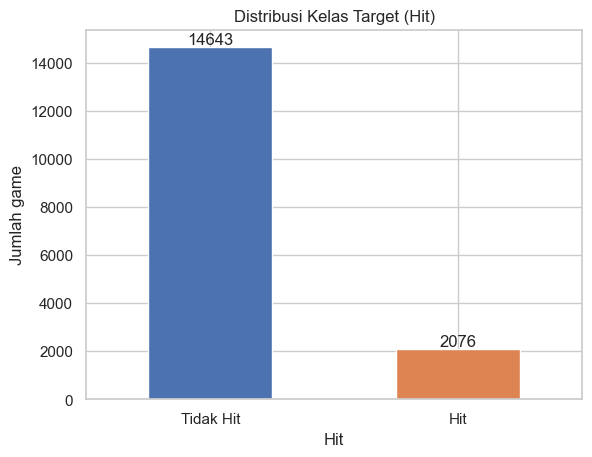

In [8]:
# Visualisasi distribusi kelas target
ax = dist.plot(kind='bar', color=['#4C72B0', '#DD8452'], rot=0)
ax.set_title('Distribusi Kelas Target (Hit)')
ax.set_ylabel('Jumlah game')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.show()

### 1.6 Ringkasan Fase 1
- Dataset berisi **16.719 baris x 16 kolom** (31 platform, 12 genre, 581 publisher, 1.696 developer).
- Target **Hit** (Global_Sales >= 1 juta): **2.076 game (12,42%)** vs Tidak Hit 14.643 (87,58%), jadi dataset **imbalanced**. Baseline akurasi menebak "Tidak Hit" semua = **87,58%**, sehingga evaluasi tidak boleh hanya memakai accuracy.
- Missing value besar: Critic_Score/Critic_Count ~51%, User_Count ~55%, Developer ~40%, Rating ~40%, User_Score ~40% + **2.425 nilai "tbd"** (kolom bertipe string).
- Kejanggalan lain: Year_of_Release kosong 269 baris dan maksimum **2020** (dataset per 2016); Name/Genre kosong 2 baris; nama game berulang (rilis multi-platform).
- Kolom penjualan dibuang dari fitur (leakage). Kandidat fitur: Platform, Year, Genre, Publisher, Critic/User Score & Count, Developer, Rating.

*Fase 2 (EDA & kualitas data) dilanjutkan di bawah.*

## 2. EDA & Investigasi Kualitas Data
Tujuan: memahami isi data dan menemukan masalah kualitas yang menentukan pilihan preprocessing di Fase 3. Semua pemeriksaan dilakukan pada salinan `eda` agar data mentah `df` tetap utuh.

In [9]:
# Salinan kerja untuk EDA (data mentah tidak diubah)
eda = df.copy()
# 'tbd' = to be determined (belum ada skor) -> jadikan NaN agar bisa dianalisis sebagai angka
eda['User_Score'] = pd.to_numeric(eda['User_Score'], errors='coerce')
print('User_Score sekarang bertipe:', eda['User_Score'].dtype)
print('Rentang User_Score:', eda['User_Score'].min(), '-', eda['User_Score'].max())
print('Rentang Critic_Score:', eda['Critic_Score'].min(), '-', eda['Critic_Score'].max())

User_Score sekarang bertipe: float64
Rentang User_Score: 0.0 - 9.7
Rentang Critic_Score: 13.0 - 98.0


### 2.1 Ringkasan masalah kualitas data

In [10]:
# Pemeriksaan kualitas data secara terstruktur
n = len(df)
cek = pd.DataFrame([
    ['Baris duplikat penuh', int(df.duplicated().sum())],
    ['Duplikat Name + Platform', int(df.duplicated(['Name', 'Platform']).sum())],
    ['Name kosong', int(df['Name'].isna().sum())],
    ['Genre kosong', int(df['Genre'].isna().sum())],
    ['Year_of_Release kosong', int(df['Year_of_Release'].isna().sum())],
    ['Year_of_Release > 2016 (di luar periode dataset)', int((df['Year_of_Release'] > 2016).sum())],
    ["User_Score = 'tbd'", int((df['User_Score'] == 'tbd').sum())],
    ['Critic_Score kosong', int(df['Critic_Score'].isna().sum())],
    ['Rating kosong', int(df['Rating'].isna().sum())],
    ['Rating langka (<10 baris)', int((df['Rating'].map(df['Rating'].value_counts()) < 10).sum())],
    ['Publisher dengan <=5 game (jumlah publisher)', int((df['Publisher'].value_counts() <= 5).sum())],
], columns=['Pemeriksaan', 'Jumlah'])
cek['Persen dari data (%)'] = (cek['Jumlah'] / n * 100).round(2)
cek

,Pemeriksaan,Jumlah,Persen dari data (%)
0,Baris duplikat penuh,0,0.00
1,Duplikat Name + Platform,5,0.03
2,Name kosong,2,0.01
3,Genre kosong,2,0.01
4,Year_of_Release kosong,269,1.61
5,Year_of_Release > 2016 (di luar periode dataset),4,0.02
6,User_Score = 'tbd',2425,14.50
7,Critic_Score kosong,8582,51.33
8,Rating kosong,6769,40.49
9,Rating langka (<10 baris),15,0.09


In [11]:
# Baris bermasalah: Name/Genre kosong dan tahun di luar periode
print(df.loc[df['Name'].isna() | df['Genre'].isna(), ['Name', 'Platform', 'Year_of_Release', 'Genre', 'Global_Sales']])
print()
print(df.loc[df['Year_of_Release'] > 2016, ['Name', 'Platform', 'Year_of_Release']])

      Name Platform  Year_of_Release Genre  Global_Sales
659    NaN      GEN           1993.0   NaN          2.39
14246  NaN      GEN           1993.0   NaN          0.03

                                                   Name Platform  \
5936                             Imagine: Makeup Artist       DS   
14086  Phantasy Star Online 2 Episode 4: Deluxe Package      PS4   
16222  Phantasy Star Online 2 Episode 4: Deluxe Package      PSV   
16385                  Brothers Conflict: Precious Baby      PSV   

       Year_of_Release  
5936            2020.0  
14086           2017.0  
16222           2017.0  
16385           2017.0  


### 2.2 Plot 1 — Persentase missing value per kolom

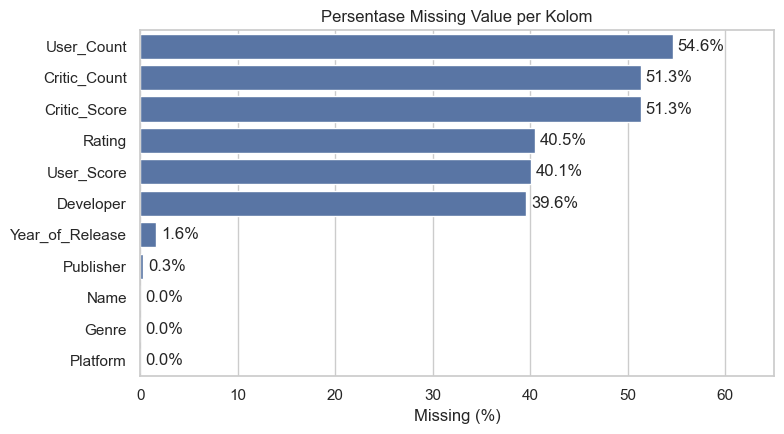

In [12]:
# Persentase missing per kolom (kolom penjualan tidak ditampilkan, tidak dipakai sebagai fitur)
miss = (df[kandidat_fitur].isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=miss.values, y=miss.index, color='#4C72B0')
ax.set_xlabel('Missing (%)'); ax.set_ylabel(''); ax.set_title('Persentase Missing Value per Kolom')
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.xlim(0, 65); plt.tight_layout(); plt.show()

**Penjelasan:** Enam kolom (`Critic_Score`, `Critic_Count`, `User_Count`, `User_Score`, `Developer`, `Rating`) kehilangan sekitar 40–55% nilainya, jauh melampaui kolom lain yang hampir lengkap. Pola ini bukan acak: data skor berasal dari Metacritic yang hanya mencakup game tertentu. Menghapus semua baris yang kosong akan membuang lebih dari separuh data, jadi diperlukan strategi imputasi, bukan penghapusan.

### 2.3 Plot 2 — Distribusi penjualan global

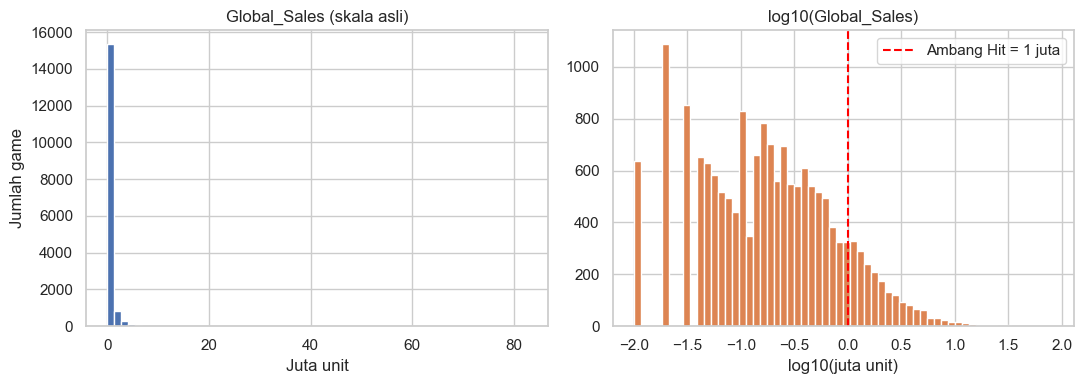

Skewness Global_Sales: 17.38
Median: 0.17 | Rata-rata: 0.534 | Maks: 82.53


In [13]:
# Distribusi Global_Sales: skala asli vs skala log
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df['Global_Sales'], bins=60, color='#4C72B0')
ax[0].set_title('Global_Sales (skala asli)'); ax[0].set_xlabel('Juta unit'); ax[0].set_ylabel('Jumlah game')
ax[1].hist(np.log10(df['Global_Sales']), bins=60, color='#DD8452')
ax[1].axvline(np.log10(THRESHOLD), color='red', ls='--', label='Ambang Hit = 1 juta')
ax[1].set_title('log10(Global_Sales)'); ax[1].set_xlabel('log10(juta unit)'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Skewness Global_Sales:', round(df['Global_Sales'].skew(), 2))
print('Median:', df['Global_Sales'].median(), '| Rata-rata:', round(df['Global_Sales'].mean(), 3), '| Maks:', df['Global_Sales'].max())

**Penjelasan:** Penjualan sangat condong ke kanan (skewness ≈ 17,4): median hanya 0,17 juta unit, sedangkan rata-rata 0,53 juta karena sedikit game blockbuster (maks 82,5 juta). Garis merah menunjukkan ambang Hit; hanya ekor kecil di kanannya yang menjadi kelas positif. Inilah sebab kelas Hit hanya 12,4% dan data tidak seimbang.

### 2.4 Plot 3 — Hit rate per Genre

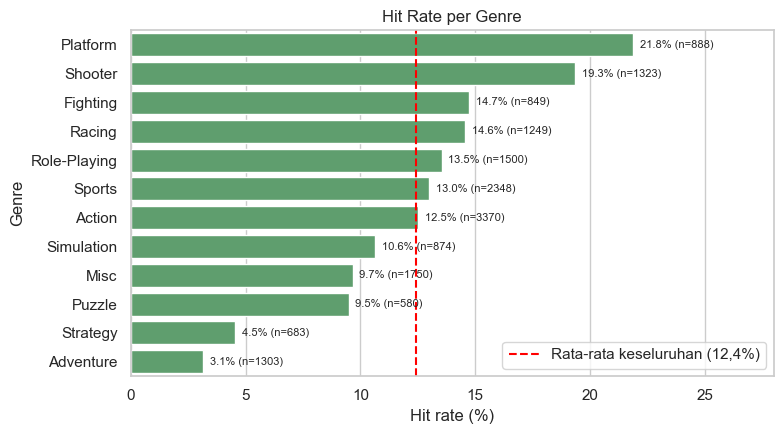

In [14]:
# Persentase Hit untuk tiap genre
g = eda.groupby('Genre')['Hit'].agg(['mean', 'count']).sort_values('mean', ascending=False)
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=g['mean'] * 100, y=g.index, color='#55A868')
ax.axvline(eda['Hit'].mean() * 100, color='red', ls='--', label='Rata-rata keseluruhan (12,4%)')
ax.set_xlabel('Hit rate (%)'); ax.set_title('Hit Rate per Genre'); ax.legend()
for i, (m, c) in enumerate(zip(g['mean'], g['count'])):
    ax.text(m * 100 + 0.3, i, f'{m*100:.1f}% (n={c})', va='center', fontsize=8)
plt.xlim(0, 28); plt.tight_layout(); plt.show()

**Penjelasan:** Genre sangat memengaruhi peluang Hit. Platform (21,8%) dan Shooter (19,3%) jauh di atas rata-rata, sedangkan Adventure (3,1%) dan Strategy (4,5%) hampir tidak pernah mencapai 1 juta unit. Selisih sebesar ini menandakan `Genre` adalah fitur yang informatif.

### 2.5 Plot 4 — Hit rate per Platform

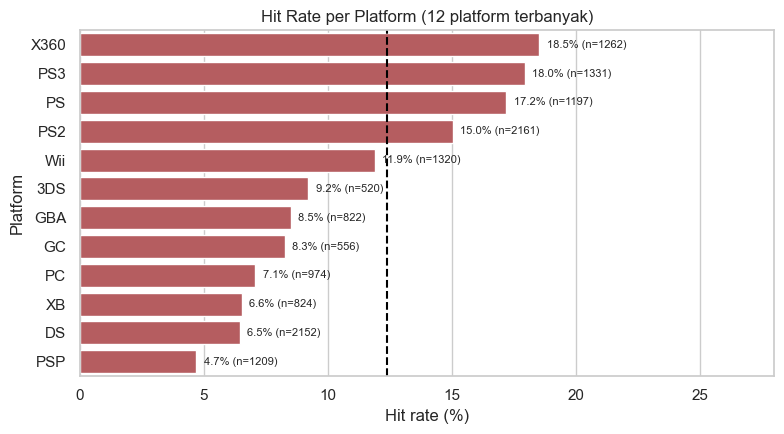

Jumlah platform unik: 31


In [15]:
# Hit rate untuk 12 platform dengan jumlah game terbanyak
top_pf = eda['Platform'].value_counts().head(12).index
p = eda[eda['Platform'].isin(top_pf)].groupby('Platform')['Hit'].agg(['mean', 'count']).sort_values('mean', ascending=False)
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=p['mean'] * 100, y=p.index, color='#C44E52')
ax.axvline(eda['Hit'].mean() * 100, color='black', ls='--')
ax.set_xlabel('Hit rate (%)'); ax.set_title('Hit Rate per Platform (12 platform terbanyak)')
for i, (m, c) in enumerate(zip(p['mean'], p['count'])):
    ax.text(m * 100 + 0.3, i, f'{m*100:.1f}% (n={c})', va='center', fontsize=8)
plt.xlim(0, 28); plt.tight_layout(); plt.show()
print('Jumlah platform unik:', eda['Platform'].nunique())

**Penjelasan:** Platform konsol rumahan seperti X360 (18,5%), PS3 (18,0%), dan PS (17,2%) punya hit rate tinggi, sedangkan konsol genggam dan PC jauh lebih rendah (PSP 4,7%, DS 6,5%, PC 7,1%). Ada 31 platform dan banyak yang berisi sedikit game, sehingga di Fase 3 platform perlu dikelompokkan agar kategorinya tidak terlalu jarang.

### 2.6 Plot 5 — Jumlah rilis per tahun

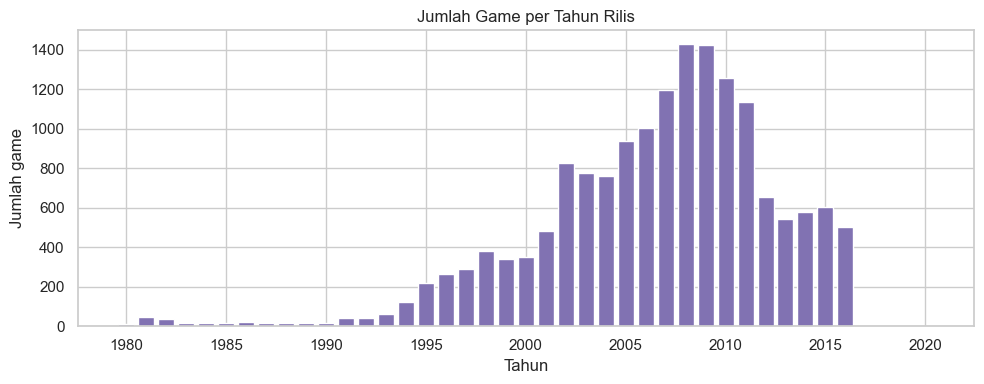

Tahun dengan rilis terbanyak: 2008 = 1427 game


In [16]:
# Jumlah game per tahun rilis
yr = eda['Year_of_Release'].value_counts().sort_index()
plt.figure(figsize=(10, 4))
plt.bar(yr.index, yr.values, color='#8172B2')
plt.title('Jumlah Game per Tahun Rilis'); plt.xlabel('Tahun'); plt.ylabel('Jumlah game')
plt.tight_layout(); plt.show()
print('Tahun dengan rilis terbanyak:', int(yr.idxmax()), '=', yr.max(), 'game')

**Penjelasan:** Jumlah rilis melonjak sejak awal 2000-an dan memuncak pada 2008 (1.427 game), lalu menurun. Tahun 2017 dan 2020 muncul walau dataset berhenti di Desember 2016; ini sekadar 4 baris tahun yang keliru atau tanggal rilis mendatang. Distribusi tidak merata antar era, sehingga tahun lebih cocok dijadikan kelompok era daripada angka mentah.

### 2.7 Plot 6 — Skor kritikus & user: Hit vs Tidak Hit

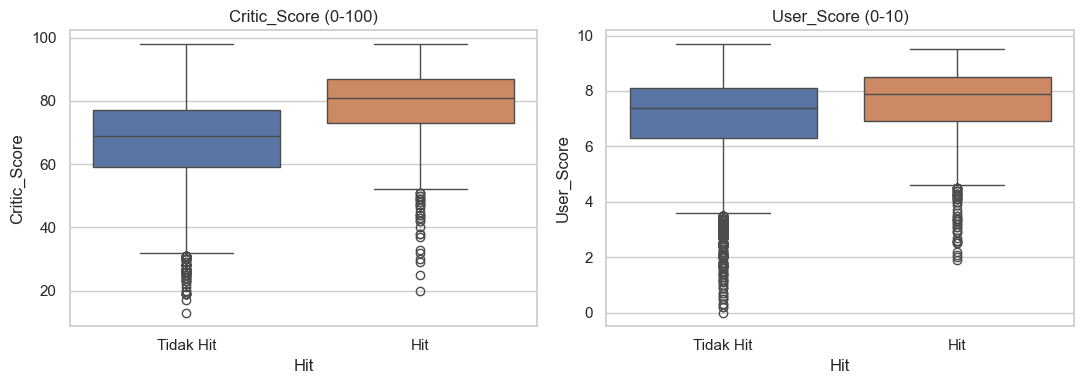

     Critic_Score  User_Score
Hit                          
0            69.0         7.4
1            81.0         7.9


In [17]:
# Perbandingan distribusi skor antara game Hit dan Tidak Hit
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=eda, x='Hit', y='Critic_Score', hue='Hit', ax=ax[0], palette=['#4C72B0', '#DD8452'], legend=False)
ax[0].set_title('Critic_Score (0-100)'); ax[0].set_xticks([0, 1], ['Tidak Hit', 'Hit'])
sns.boxplot(data=eda, x='Hit', y='User_Score', hue='Hit', ax=ax[1], palette=['#4C72B0', '#DD8452'], legend=False)
ax[1].set_title('User_Score (0-10)'); ax[1].set_xticks([0, 1], ['Tidak Hit', 'Hit'])
plt.tight_layout(); plt.show()
print(eda.groupby('Hit')[['Critic_Score', 'User_Score']].median())

**Penjelasan:** Median `Critic_Score` game Hit (81) lebih tinggi dari Tidak Hit (69), dan seluruh kotak Hit berada di atas kotak Tidak Hit, sehingga `Critic_Score` informatif. Pada `User_Score` selisih mediannya lebih kecil (7,9 vs 7,4) dan kedua kotak banyak tumpang tindih. Tidak Hit juga punya banyak nilai rendah ekstrem (outlier bawah). Skala kedua skor berbeda (0–100 vs 0–10), jadi perlu diseragamkan sebelum dipakai bersama.

### 2.8 Plot 7 — Apakah 'tidak ada skor' itu sendiri informasi?

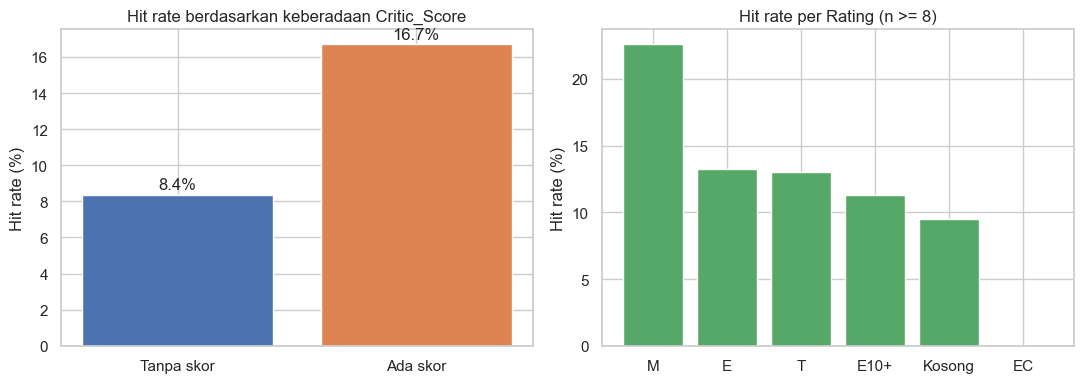

In [18]:
# Hit rate berdasarkan ada/tidaknya skor kritikus, dan berdasarkan Rating
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
has = eda.groupby(eda['Critic_Score'].notna())['Hit'].mean() * 100
ax[0].bar(['Tanpa skor', 'Ada skor'], has.values, color=['#4C72B0', '#DD8452'])
ax[0].set_title('Hit rate berdasarkan keberadaan Critic_Score'); ax[0].set_ylabel('Hit rate (%)')
for i, v in enumerate(has.values):
    ax[0].text(i, v + 0.3, f'{v:.1f}%', ha='center')
r = eda.assign(Rating=eda['Rating'].fillna('Kosong')).groupby('Rating')['Hit'].agg(['mean', 'count'])
r = r[r['count'] >= 8].sort_values('mean', ascending=False)
ax[1].bar(r.index, r['mean'] * 100, color='#55A868')
ax[1].set_title('Hit rate per Rating (n >= 8)'); ax[1].set_ylabel('Hit rate (%)')
plt.tight_layout(); plt.show()

**Penjelasan:** Game tanpa skor kritikus hanya 8,4% Hit, sedangkan yang punya skor 16,7% — dua kali lipat. Jadi missing di sini membawa informasi (game kecil jarang diulas), dan membuang atau mengisinya tanpa penanda akan menghilangkan sinyal itu. Pada Rating, `M` (22,6%) tertinggi dan data kosong 9,5%.

### 2.9 Plot 8 — Korelasi fitur numerik

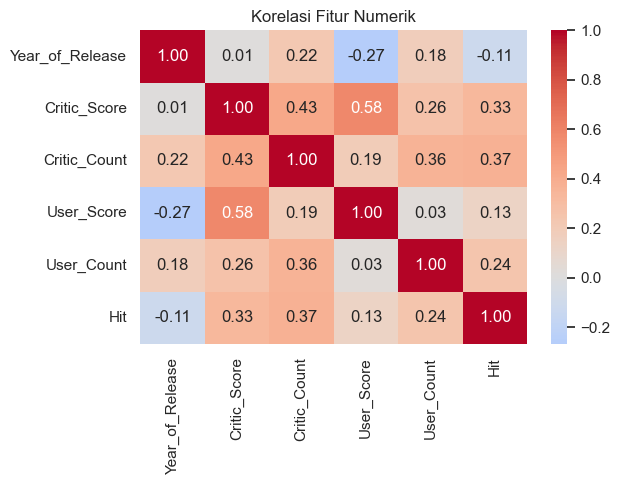

In [19]:
# Matriks korelasi fitur numerik terhadap target
num = eda[['Year_of_Release', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count', 'Hit']]
plt.figure(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi Fitur Numerik'); plt.tight_layout(); plt.show()

**Penjelasan:** `Critic_Count` (0,37) dan `Critic_Score` (0,33) paling berkorelasi dengan Hit. `Critic_Score` dan `User_Score` saling berkorelasi (0,58), yang berarti asumsi independensi Naive Bayes kurang terpenuhi. `Year_of_Release` berkorelasi negatif lemah (−0,11).

### 2.10 Plot 9 — Outlier pada User_Count

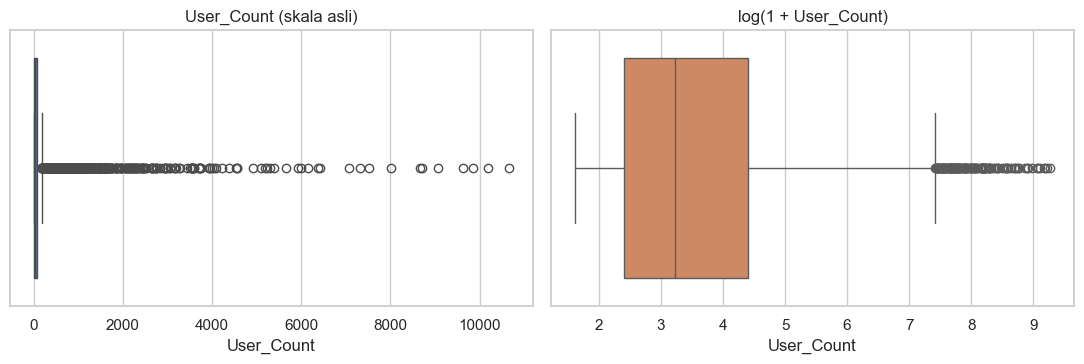

count     7590.0
mean       162.2
std        561.3
min          4.0
25%         10.0
50%         24.0
75%         81.0
max      10665.0
Name: User_Count, dtype: float64


In [20]:
# Sebaran User_Count: skala asli vs log
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x=eda['User_Count'].dropna(), ax=ax[0], color='#4C72B0'); ax[0].set_title('User_Count (skala asli)')
sns.boxplot(x=np.log1p(eda['User_Count'].dropna()), ax=ax[1], color='#DD8452'); ax[1].set_title('log(1 + User_Count)')
plt.tight_layout(); plt.show()
print(eda['User_Count'].describe().round(1))

**Penjelasan:** `User_Count` sangat timpang: median hanya 24, tetapi maksimum 10.665 sehingga box plot asli hampir rata di kiri. Transformasi log merapikan sebaran. Hal serupa berlaku untuk `Critic_Count`, jadi keduanya akan di-log-transform di Fase 3.

### 2.11 Kesimpulan Fase 2 — masalah kualitas & implikasi preprocessing
| No | Temuan | Dampak | Rencana di Fase 3 |
|---|---|---|---|
| 1 | Missing 40–55% pada skor, count, Developer, Rating | Menghapus baris membuang > separuh data | Imputasi + kolom penanda `has_critic_score` |
| 2 | `User_Score` memuat 2.425 nilai 'tbd' (string) | Kolom terbaca teks | 'tbd' → NaN, ubah ke float, skala ×10 |
| 3 | Skala skor berbeda (0–100 vs 0–10) | Tidak sebanding | Seragamkan ke 0–100 |
| 4 | Tahun kosong (269) dan 4 baris > 2016 | Nilai tidak valid | Isi/netralkan, kelompokkan menjadi era |
| 5 | Name/Genre kosong (2 baris) | Baris tidak usable | Hapus 2 baris tersebut |
| 6 | 31 platform, 581 publisher, 1.696 developer | Kategori terlalu banyak/jarang | Kelompokkan platform; Publisher top-N, sisanya 'Other'; Developer tidak dipakai |
| 7 | Rating langka (EC, K-A, RP, AO) | Kategori hampir kosong | Gabungkan ke 'Lainnya', kosong → 'Unknown' |
| 8 | `Count` sangat timpang | Outlier mengganggu | Log-transform |
| 9 | Kelas Hit hanya 12,4% | Model bias ke 'Tidak Hit' | Split stratified, pertimbangkan class weight/prior seimbang |
| 10 | `Name` unik per game | Tidak generalisasi | Tidak dipakai sebagai fitur |
| 11 | Kolom penjualan = sumber label | Data leakage | Dibuang dari fitur |

*Lanjut ke Fase 3: Preprocessing.*

## 3. Preprocessing
Urutan kerja dibuat agar **tidak ada kebocoran informasi dari data uji**:
1. **Cleaning tanpa statistik** (aturan tetap, aman diterapkan ke seluruh data): hapus baris rusak, perbaiki tipe, buat fitur turunan.
2. **Split stratified 80/20** (manual).
3. **Transformasi yang "belajar" dari data** (median imputasi, daftar publisher teratas) dihitung **hanya dari data latih**, lalu diterapkan ke data latih dan uji.

### 3.1 Tabel pendekatan preprocessing
| No | Masalah (dari Fase 2) | Teknik | Alasan | Hasil yang diharapkan |
|---|---|---|---|---|
| 1 | Name/Genre kosong (2 baris) | Hapus baris | Tanpa genre & nama baris tidak bermakna; hanya 0,01% data | Tidak ada baris tanpa identitas |
| 2 | `User_Score` berisi 'tbd' (string) | 'tbd' → NaN, ubah ke float | 'tbd' artinya skor belum ada, setara missing | Kolom numerik valid |
| 3 | Skala skor beda (0–100 vs 0–10) | `User_Score` × 10 | Agar kedua skor sebanding | Kedua skor berskala 0–100 |
| 4 | Missing skor ~40–51% dan bermakna | Kolom penanda `has_critic_score`, `has_user_score` | Fase 2: tanpa skor → hit rate 8,4% vs 16,7% | Informasi "tidak diulas" tetap tersimpan |
| 5 | Missing skor | Imputasi **median per Genre** (dari data latih) | Median tahan outlier; skor wajar berbeda per genre; hapus baris membuang > 50% data | Tidak ada NaN pada skor |
| 6 | `Critic_Count`/`User_Count` kosong & sangat timpang | Isi 0 lalu `log(1 + x)` | Kosong = tidak ada ulasan = 0; log meredam outlier (maks 10.665) | Sebaran lebih simetris |
| 7 | Tahun kosong & > 2016 | Tahun > 2016 → NaN, lalu kelompokkan ke **Era** (+ 'Unknown') | Tahun tidak valid; era lebih stabil daripada angka tahun | Fitur kategorikal 5 nilai |
| 8 | 31 platform, banyak yang jarang | Kelompokkan jadi **keluarga + jenis** (rumahan/genggam) | Fase 2: konsol rumahan hit rate jauh di atas genggam | 7 kategori platform |
| 9 | 581 publisher | **10 publisher teratas** (data latih), sisanya 'Other' | Kategori jarang tidak bisa dipelajari | 11 kategori publisher |
| 10 | Rating langka & 40% kosong | EC/K-A/RP/AO → 'Other', kosong → 'Unknown' | Kategori dengan < 10 data tidak stabil | 6 kategori rating |
| 11 | `Name`, `Developer` | Tidak dipakai | Name unik per game; Developer 1.696 kategori & 40% kosong | Fitur lebih ringkas |
| 12 | Kolom penjualan | Dibuang | Sumber label (leakage) | Evaluasi jujur |
| 13 | Kelas tidak seimbang (12,4%) | **Split stratified** | Proporsi Hit sama di latih & uji | Hit ≈ 12,4% di kedua set |

### 3.2 Cleaning (aturan tetap)

In [21]:
# Mulai dari data mentah + kolom target
data = df.copy()
n_awal = len(data)

# (1) Hapus baris tanpa Name/Genre
data = data.dropna(subset=['Name', 'Genre']).reset_index(drop=True)

# (2)(3) 'tbd' -> NaN, ubah ke float, lalu samakan skala ke 0-100
data['User_Score'] = pd.to_numeric(data['User_Score'], errors='coerce') * 10

# (4) Penanda keberadaan skor (dibuat SEBELUM imputasi)
data['has_critic_score'] = data['Critic_Score'].notna().astype(int)
data['has_user_score'] = data['User_Score'].notna().astype(int)

# (6) Count kosong = tidak ada ulasan -> 0, lalu log(1 + x)
for col in ['Critic_Count', 'User_Count']:
    data['log_' + col] = np.log1p(data[col].fillna(0))

# (7) Tahun di luar periode dataset (> 2016) dianggap tidak valid, lalu dikelompokkan ke era
data.loc[data['Year_of_Release'] > 2016, 'Year_of_Release'] = np.nan
def ke_era(y):
    if pd.isna(y): return 'Unknown'
    if y < 2000:   return '<2000'
    if y < 2005:   return '2000-2004'
    if y < 2010:   return '2005-2009'
    return '2010-2016'
data['Era'] = data['Year_of_Release'].apply(ke_era)

# (8) Kelompok platform: keluarga + jenis (rumahan/genggam)
peta_platform = {
    'Wii': 'Nintendo_Home', 'WiiU': 'Nintendo_Home', 'GC': 'Nintendo_Home', 'N64': 'Nintendo_Home',
    'SNES': 'Nintendo_Home', 'NES': 'Nintendo_Home',
    'DS': 'Nintendo_Handheld', '3DS': 'Nintendo_Handheld', 'GBA': 'Nintendo_Handheld', 'GB': 'Nintendo_Handheld',
    'PS': 'Sony_Home', 'PS2': 'Sony_Home', 'PS3': 'Sony_Home', 'PS4': 'Sony_Home',
    'PSP': 'Sony_Handheld', 'PSV': 'Sony_Handheld',
    'XB': 'Microsoft', 'X360': 'Microsoft', 'XOne': 'Microsoft',
    'PC': 'PC',
}
data['Platform_Group'] = data['Platform'].map(peta_platform).fillna('Other')  # konsol lawas/langka

# (10) Rating: gabungkan kategori langka, kosong -> Unknown
data['Rating_Clean'] = data['Rating'].replace({'EC': 'Other', 'K-A': 'Other', 'RP': 'Other', 'AO': 'Other'}).fillna('Unknown')

print(f'Baris: {n_awal} -> {len(data)} (dihapus {n_awal - len(data)})')
print('\nPlatform_Group:'); print(data['Platform_Group'].value_counts())

Baris: 16719 -> 16717 (dihapus 2)

Platform_Group:
Platform_Group
Sony_Home            5082
Nintendo_Handheld    3592
Nintendo_Home        2679
Microsoft            2333
Sony_Handheld        1641
PC                    974
Other                 416
Name: count, dtype: int64


### 3.3 Split stratified 80/20 (manual, tanpa library ML)

In [22]:
def stratified_split(y, test_size=0.2, seed=SEED):
    """Bagi indeks per kelas secara acak agar proporsi kelas sama di data latih & uji."""
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for kelas in np.unique(y):
        idx = np.where(y == kelas)[0]          # semua indeks milik kelas ini
        rng.shuffle(idx)                       # acak urutannya
        n_test = int(round(len(idx) * test_size))
        idx_test.extend(idx[:n_test])          # sebagian ke data uji
        idx_train.extend(idx[n_test:])         # sisanya ke data latih
    return np.array(sorted(idx_train)), np.array(sorted(idx_test))

idx_tr, idx_te = stratified_split(data['Hit'].values)
train = data.iloc[idx_tr].reset_index(drop=True)
test = data.iloc[idx_te].reset_index(drop=True)

# Cek proporsi kelas di tiap set
print(pd.DataFrame({
    'Jumlah baris': [len(data), len(train), len(test)],
    'Hit': [data['Hit'].sum(), train['Hit'].sum(), test['Hit'].sum()],
    'Hit (%)': [round(d['Hit'].mean() * 100, 2) for d in (data, train, test)],
}, index=['Semua', 'Latih (80%)', 'Uji (20%)']))

             Jumlah baris   Hit  Hit (%)
Semua               16717  2075    12.41
Latih (80%)         13374  1660    12.41
Uji (20%)            3343   415    12.41


### 3.4 Transformasi yang dipelajari dari data latih

In [23]:
class Preprocessor:
    """Menyimpan statistik dari data latih, lalu menerapkannya ke data apa pun (latih/uji)."""

    def fit(self, tr, top_n=10):
        # (5) Median skor per Genre + median global sebagai cadangan
        self.median_genre = tr.groupby('Genre')[['Critic_Score', 'User_Score']].median()
        self.median_global = tr[['Critic_Score', 'User_Score']].median()
        # (9) Publisher teratas berdasarkan jumlah game di data latih
        self.top_publisher = tr['Publisher'].value_counts().head(top_n).index.tolist()
        return self

    def transform(self, d):
        d = d.copy()
        for col in ['Critic_Score', 'User_Score']:
            isi = d['Genre'].map(self.median_genre[col]).fillna(self.median_global[col])
            d[col] = d[col].fillna(isi)
        d['Publisher_Top'] = d['Publisher'].where(d['Publisher'].isin(self.top_publisher), 'Other')
        return d

prep = Preprocessor().fit(train)
train_p = prep.transform(train)
test_p = prep.transform(test)

print('Median imputasi per Genre (dihitung dari data latih):')
print(prep.median_genre.round(1))
print('\nPublisher teratas:', prep.top_publisher)

Median imputasi per Genre (dihitung dari data latih):
              Critic_Score  User_Score
Genre                                 
Action                68.0        73.0
Adventure             66.0        76.0
Fighting              72.0        76.0
Misc                  68.0        71.0
Platform              69.0        77.0
Puzzle                70.0        75.0
Racing                69.0        74.0
Role-Playing          74.0        79.0
Shooter               73.0        75.0
Simulation            70.0        76.0
Sports                75.0        74.0
Strategy              73.0        78.5

Publisher teratas: ['Electronic Arts', 'Activision', 'Ubisoft', 'Namco Bandai Games', 'Konami Digital Entertainment', 'THQ', 'Nintendo', 'Sony Computer Entertainment', 'Sega', 'Take-Two Interactive']


### 3.5 Fitur akhir

In [24]:
FITUR_NUM = ['Critic_Score', 'User_Score', 'log_Critic_Count', 'log_User_Count']
FITUR_KAT = ['Genre', 'Platform_Group', 'Era', 'Rating_Clean', 'Publisher_Top',
             'has_critic_score', 'has_user_score']
FITUR = FITUR_NUM + FITUR_KAT
TARGET = 'Hit'

X_train, y_train = train_p[FITUR], train_p[TARGET].values
X_test, y_test = test_p[FITUR], test_p[TARGET].values

# Ringkasan fitur akhir
pd.DataFrame({
    'Fitur': FITUR,
    'Jenis': ['Numerik'] * len(FITUR_NUM) + ['Kategorikal'] * len(FITUR_KAT),
    'Jumlah nilai unik': [X_train[c].nunique() for c in FITUR],
    'Missing di latih': [int(X_train[c].isna().sum()) for c in FITUR],
    'Missing di uji': [int(X_test[c].isna().sum()) for c in FITUR],
})

,Fitur,Jenis,Jumlah nilai unik,Missing di latih,Missing di uji
0,Critic_Score,Numerik,82,0,0
1,User_Score,Numerik,96,0,0
2,log_Critic_Count,Numerik,107,0,0
3,log_User_Count,Numerik,784,0,0
4,Genre,Kategorikal,12,0,0
5,Platform_Group,Kategorikal,7,0,0
6,Era,Kategorikal,5,0,0
7,Rating_Clean,Kategorikal,6,0,0
8,Publisher_Top,Kategorikal,11,0,0
9,has_critic_score,Kategorikal,2,0,0


In [25]:
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
X_train.head()

X_train: (13374, 11) | X_test: (3343, 11)


,Critic_Score,User_Score,log_Critic_Count,log_User_Count,Genre,Platform_Group,Era,Rating_Clean,Publisher_Top,has_critic_score,has_user_score
0,76.0,80.0,3.951244,5.777652,Sports,Nintendo_Home,2005-2009,E,Nintendo,1,1
1,69.0,77.0,0.000000,0.000000,Platform,Nintendo_Home,<2000,Unknown,Nintendo,0,0
2,82.0,83.0,4.304065,6.565265,Racing,Nintendo_Home,2005-2009,E,Nintendo,1,1
3,80.0,80.0,4.304065,5.262690,Sports,Nintendo_Home,2005-2009,E,Nintendo,1,1
4,70.0,75.0,0.000000,0.000000,Puzzle,Nintendo_Handheld,<2000,Unknown,Nintendo,0,0


### 3.6 Bukti sebelum vs sesudah preprocessing

In [26]:
# Perbandingan missing value sebelum dan sesudah (pada kolom yang dipakai)
kolom_asal = {'Critic_Score': 'Critic_Score', 'User_Score': 'User_Score',
              'log_Critic_Count': 'Critic_Count', 'log_User_Count': 'User_Count',
              'Era': 'Year_of_Release', 'Rating_Clean': 'Rating', 'Publisher_Top': 'Publisher'}
before_after = pd.DataFrame({
    'Kolom asal': list(kolom_asal.values()),
    'Missing sebelum (%)': [round(df[c].isna().mean() * 100, 1) if c != 'User_Score'
                            else round(pd.to_numeric(df[c], errors='coerce').isna().mean() * 100, 1)
                            for c in kolom_asal.values()],
    'Kolom hasil': list(kolom_asal.keys()),
    'Missing sesudah (%)': [round(pd.concat([X_train, X_test])[c].isna().mean() * 100, 1) for c in kolom_asal],
})
before_after

,Kolom asal,Missing sebelum (%),Kolom hasil,Missing sesudah (%)
0,Critic_Score,51.3,Critic_Score,0.0
1,User_Score,54.6,User_Score,0.0
2,Critic_Count,51.3,log_Critic_Count,0.0
3,User_Count,54.6,log_User_Count,0.0
4,Year_of_Release,1.6,Era,0.0
5,Rating,40.5,Rating_Clean,0.0
6,Publisher,0.3,Publisher_Top,0.0


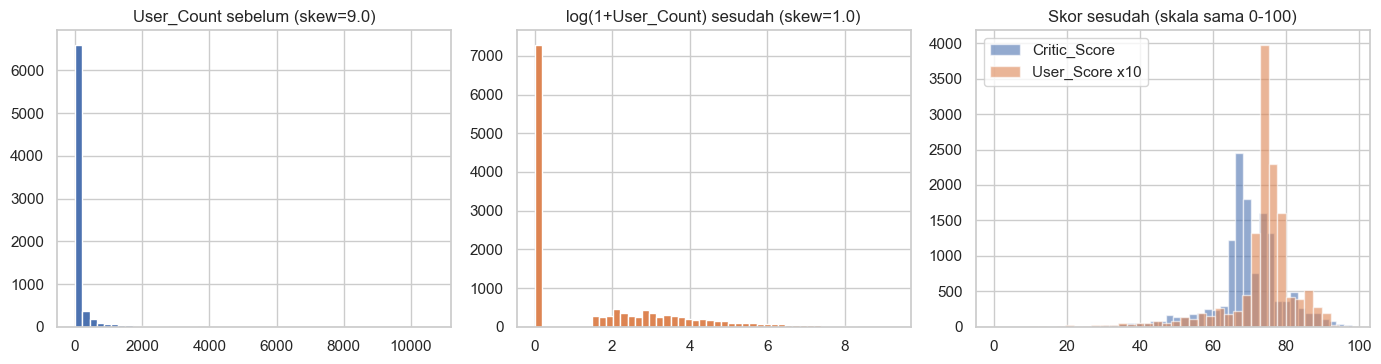

In [27]:
# Sebaran Count sebelum vs sesudah log-transform, dan skala skor sebelum vs sesudah
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(df['User_Count'].dropna(), bins=50, color='#4C72B0')
ax[0].set_title(f"User_Count sebelum (skew={df['User_Count'].skew():.1f})")
ax[1].hist(train_p['log_User_Count'], bins=50, color='#DD8452')
ax[1].set_title(f"log(1+User_Count) sesudah (skew={train_p['log_User_Count'].skew():.1f})")
ax[2].hist(train_p['Critic_Score'], bins=40, alpha=0.6, label='Critic_Score')
ax[2].hist(train_p['User_Score'], bins=40, alpha=0.6, label='User_Score x10')
ax[2].set_title('Skor sesudah (skala sama 0-100)'); ax[2].legend()
plt.tight_layout(); plt.show()

**Penjelasan:** Log-transform menurunkan skewness `User_Count` dari 9,0 menjadi 1,0, sehingga nilai ekstrem tidak lagi mendominasi. Masih ada lonjakan di 0 karena 54,6% game memang tidak punya ulasan user; informasi ini juga tercatat di `has_user_score`. Pada plot kanan, kedua skor kini berskala 0–100. Terlihat puncak tajam di sekitar 68–79: itu efek imputasi median per Genre. Imputasi membuat sebaran skor lebih sempit, sehingga model tetap butuh `has_critic_score`/`has_user_score` untuk membedakan skor asli dari skor isian.

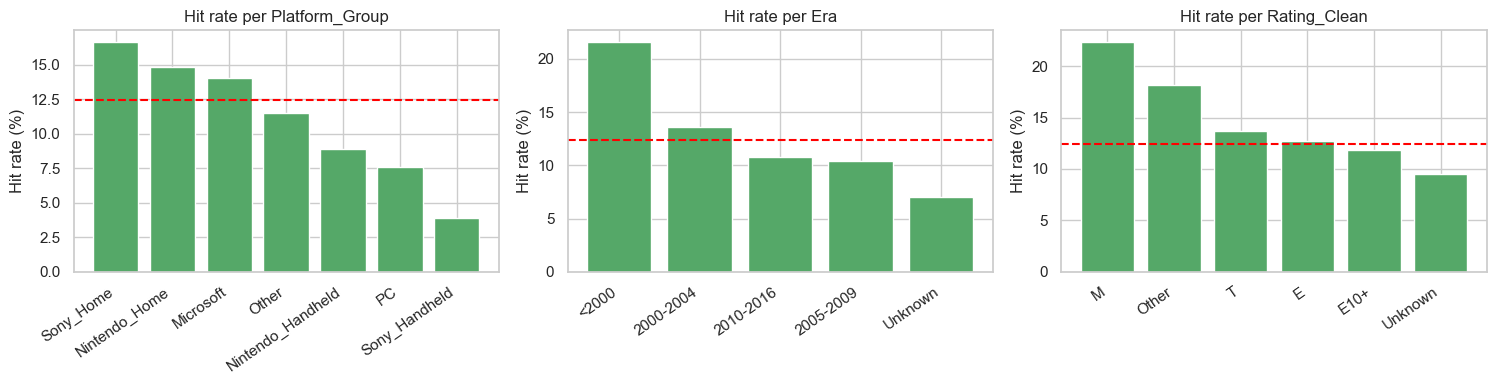

In [28]:
# Apakah fitur hasil preprocessing tetap membawa sinyal? Hit rate per kategori di data latih
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['Platform_Group', 'Era', 'Rating_Clean']):
    r = train_p.groupby(col)['Hit'].mean().sort_values(ascending=False) * 100
    a.bar(r.index, r.values, color='#55A868')
    a.axhline(train_p['Hit'].mean() * 100, color='red', ls='--')
    a.set_title(f'Hit rate per {col}'); a.set_ylabel('Hit rate (%)'); plt.setp(a.get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.show()

**Penjelasan:** Fitur hasil pengelompokan tetap membedakan peluang Hit dengan jelas. Konsol rumahan Sony/Nintendo/Microsoft berada di atas rata-rata, sedangkan Sony_Handheld hanya sekitar 4%. Era <2000 justru tertinggi (sekitar 22%); kemungkinan besar karena *survivorship bias*: game lama yang tercatat di dataset cenderung yang laris saja. Rating `M` tertinggi (sekitar 22%) dan `Unknown` terendah. Artinya pengelompokan meringkas kategori tanpa menghilangkan sinyal.

### 3.7 Ringkasan Fase 3
- Data bersih: **16.717 baris** (2 baris tanpa Name/Genre dihapus), **11 fitur** (4 numerik + 7 kategorikal), **0 missing** di data latih maupun uji.
- Split stratified manual: **13.374 latih / 3.343 uji**, proporsi Hit sama persis **12,41%** di kedua set.
- Median imputasi dan daftar 10 publisher teratas dihitung **hanya dari data latih** (kelas `Preprocessor`), jadi tidak ada informasi data uji yang bocor ke model.
- Hasil yang diharapkan tercapai: skor berskala sama 0–100, skewness `User_Count` turun 9,0 → 1,0, kategori jarang dirangkum (31 platform → 7, 581 publisher → 11, 8 rating → 6).
- Catatan untuk analisis nanti: imputasi menyempitkan sebaran skor, dan `Critic_Score`–`User_Score` tetap berkorelasi (melanggar asumsi Naive Bayes).

*Lanjut ke Fase 4: Decision Tree manual.*

## 4. Decision Tree (implementasi manual)

### 4.1 Konsep
Decision Tree memprediksi kelas dengan serangkaian pertanyaan ya/tidak terhadap fitur, tersusun seperti pohon:
- **Root node**: pertanyaan pertama, berisi seluruh data latih.
- **Internal node**: pertanyaan lanjutan (*split*), misalnya `Critic_Score <= 75.5?` atau `Genre == Shooter?`.
- **Leaf node**: ujung pohon yang memberi prediksi, yaitu kelas mayoritas data latih di leaf tersebut.

Pohon dibangun **dari atas ke bawah secara rekursif (greedy)**: di setiap node dicari split yang paling "memurnikan" data, lalu proses diulang untuk anak kiri dan kanan sampai kriteria berhenti terpenuhi.

### 4.2 Ukuran ketidakmurnian (impurity)
Dengan $p_k$ = proporsi kelas $k$ di sebuah node:

- **Gini impurity**: $G = 1 - \sum_k p_k^2$ — bernilai 0 bila node murni, maksimum 0,5 untuk 2 kelas seimbang.
- **Entropy**: $H = -\sum_k p_k \log_2 p_k$ — bernilai 0 bila murni, maksimum 1 untuk 2 kelas seimbang.

**Information Gain** sebuah split yang membagi node induk (n data) menjadi anak kiri ($n_L$) dan kanan ($n_R$):

$$IG = I(\text{induk}) - \frac{n_L}{n} I(\text{kiri}) - \frac{n_R}{n} I(\text{kanan})$$

dengan $I$ adalah Gini atau Entropy. Split terbaik = split dengan IG terbesar.

### 4.3 Cara mencari split
- **Fitur numerik**: data diurutkan, kandidat threshold adalah **titik tengah dua nilai berurutan yang berbeda**. Kondisi: `x <= threshold` → kiri.
- **Fitur kategorikal**: kandidat adalah **setiap kategori (one-vs-rest)**. Kondisi: `x == kategori` → kiri.

### 4.4 Kriteria berhenti (hyperparameter)
- `max_depth`: kedalaman maksimum pohon.
- `min_samples_split`: node dengan data kurang dari nilai ini tidak dipecah lagi.
- Node sudah murni, atau tidak ada split dengan IG > 0.

### 4.5 Penanganan kelas tidak seimbang (`class_weight`)
Dengan `class_weight='balanced'`, setiap data diberi bobot $w_k = \frac{n}{2 \cdot n_k}$ (kelas jarang mendapat bobot lebih besar). Proporsi $p_k$ pada rumus impurity dan prediksi leaf dihitung dari **jumlah bobot**, bukan jumlah data. Untuk data ini, bobot Hit ≈ 4,0 dan Tidak Hit ≈ 0,57.

### 4.6 Contoh hitungan manual (8 data)
| No | Critic_Score | Genre | Hit |
|---|---|---|---|
| 1 | 85 | Shooter | 1 |
| 2 | 90 | Shooter | 1 |
| 3 | 60 | Puzzle | 0 |
| 4 | 70 | Action | 0 |
| 5 | 88 | Action | 0 |
| 6 | 55 | Puzzle | 0 |
| 7 | 65 | Shooter | 0 |
| 8 | 92 | Action | 1 |

**Node induk**: 3 Hit, 5 Tidak Hit → $G = 1 - (3/8)^2 - (5/8)^2 = 1 - 0{,}1406 - 0{,}3906 = 0{,}4688$

**Kandidat A — `Critic_Score <= 77.5`** (titik tengah 70 dan 85):
- Kiri {60, 70, 55, 65}: 0 Hit dari 4 → $G_L = 0$
- Kanan {85, 90, 88, 92}: 3 Hit dari 4 → $G_R = 1 - 0{,}75^2 - 0{,}25^2 = 0{,}375$
- $IG = 0{,}4688 - \frac{4}{8}(0) - \frac{4}{8}(0{,}375) = \mathbf{0{,}2813}$

**Kandidat B — `Genre == Shooter`**:
- Kiri {1, 2, 7}: 2 Hit dari 3 → $G_L = 1 - (2/3)^2 - (1/3)^2 = 0{,}4444$
- Kanan {3, 4, 5, 6, 8}: 1 Hit dari 5 → $G_R = 1 - 0{,}2^2 - 0{,}8^2 = 0{,}32$
- $IG = 0{,}4688 - \frac{3}{8}(0{,}4444) - \frac{5}{8}(0{,}32) = \mathbf{0{,}1021}$

Kandidat A memberi IG lebih besar, sehingga root memakai `Critic_Score <= 77.5`. Sel kode di bawah memverifikasi hitungan ini dengan implementasi manual.

### 4.7 Flowchart

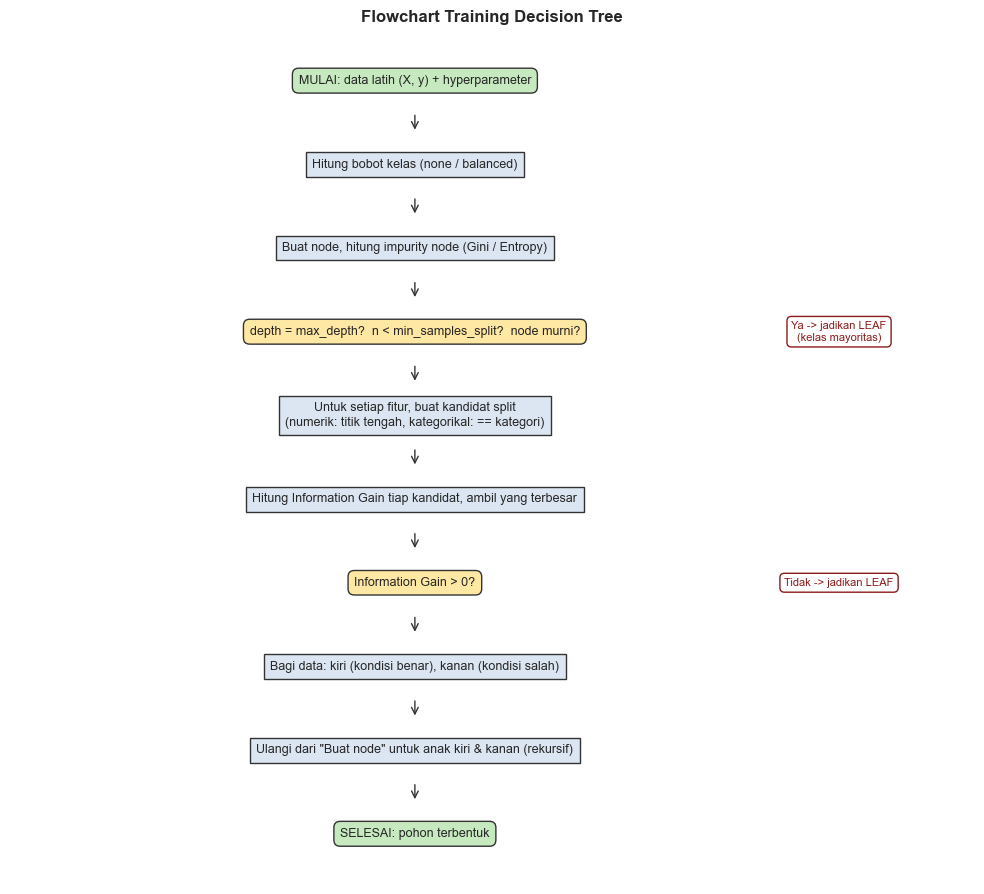

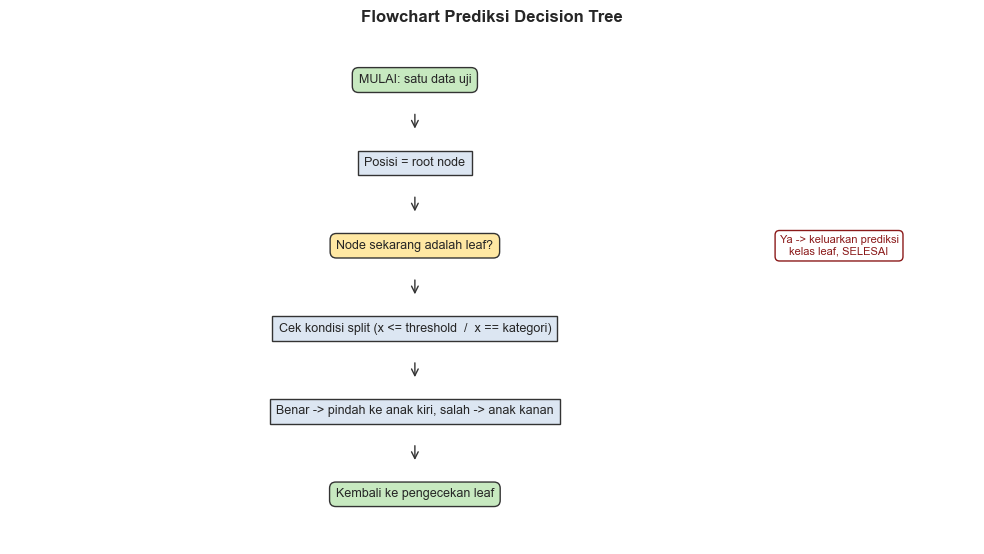

In [29]:
def gambar_flowchart(langkah, judul):
    """Menggambar flowchart vertikal sederhana.
    langkah = list (teks, jenis, keterangan_cabang); jenis: terminal / proses / keputusan."""
    warna = {'terminal': '#C7E9C0', 'proses': '#DCE6F2', 'keputusan': '#FFE8A3'}
    n = len(langkah)
    fig, ax = plt.subplots(figsize=(10, 0.85 * n + 0.6))
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, n - 0.4); ax.axis('off')
    for i, (teks, jenis, cabang) in enumerate(langkah):
        y = n - 1 - i
        gaya = 'square,pad=0.5' if jenis == 'proses' else 'round,pad=0.5'
        ax.text(4.2, y, teks, ha='center', va='center', fontsize=9,
                bbox=dict(boxstyle=gaya, fc=warna[jenis], ec='#333'))
        if cabang:   # cabang keluar dari kotak keputusan
            ax.text(8.6, y, cabang, ha='center', va='center', fontsize=8, color='#8B1A1A',
                    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#8B1A1A'))
        if i < n - 1:  # panah ke langkah berikutnya
            ax.annotate('', xy=(4.2, y - 0.62), xytext=(4.2, y - 0.38),
                        arrowprops=dict(arrowstyle='->', color='#333'))
    ax.set_title(judul, fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()

gambar_flowchart([
    ('MULAI: data latih (X, y) + hyperparameter', 'terminal', None),
    ('Hitung bobot kelas (none / balanced)', 'proses', None),
    ('Buat node, hitung impurity node (Gini / Entropy)', 'proses', None),
    ('depth = max_depth?  n < min_samples_split?  node murni?', 'keputusan', 'Ya -> jadikan LEAF\n(kelas mayoritas)'),
    ('Untuk setiap fitur, buat kandidat split\n(numerik: titik tengah, kategorikal: == kategori)', 'proses', None),
    ('Hitung Information Gain tiap kandidat, ambil yang terbesar', 'proses', None),
    ('Information Gain > 0?', 'keputusan', 'Tidak -> jadikan LEAF'),
    ('Bagi data: kiri (kondisi benar), kanan (kondisi salah)', 'proses', None),
    ('Ulangi dari "Buat node" untuk anak kiri & kanan (rekursif)', 'proses', None),
    ('SELESAI: pohon terbentuk', 'terminal', None),
], 'Flowchart Training Decision Tree')

gambar_flowchart([
    ('MULAI: satu data uji', 'terminal', None),
    ('Posisi = root node', 'proses', None),
    ('Node sekarang adalah leaf?', 'keputusan', 'Ya -> keluarkan prediksi\nkelas leaf, SELESAI'),
    ('Cek kondisi split (x <= threshold  /  x == kategori)', 'proses', None),
    ('Benar -> pindah ke anak kiri, salah -> anak kanan', 'proses', None),
    ('Kembali ke pengecekan leaf', 'terminal', None),
], 'Flowchart Prediksi Decision Tree')

### 4.8 Implementasi

In [30]:
def impurity(p1, criterion='gini'):
    """Impurity untuk 2 kelas; p1 = proporsi (berbobot) kelas Hit. Bisa menerima array."""
    p1 = np.clip(p1, 0, 1)
    p0 = 1 - p1
    if criterion == 'gini':
        return 1 - p1 ** 2 - p0 ** 2
    with np.errstate(divide='ignore', invalid='ignore'):      # log2(0) diabaikan, 0*log 0 = 0
        return -(np.where(p1 > 0, p1 * np.log2(p1), 0) + np.where(p0 > 0, p0 * np.log2(p0), 0))


class DecisionTreeManual:
    """Decision Tree klasifikasi biner, ditulis dari nol (hanya numpy/pandas)."""

    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 class_weight=None, cat_features=None):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.class_weight = class_weight
        self.cat_features = cat_features if cat_features is not None else FITUR_KAT

    # ---------- encoding: kategori -> kode integer (pemetaan dari data latih) ----------
    def _encode(self, X):
        M = np.empty((len(X), len(self.features)))
        for j, f in enumerate(self.features):
            if self.is_cat[j]:
                # kategori yang tidak pernah muncul di data latih diberi kode -1
                M[:, j] = X[f].astype(str).map(self.cat_map[f]).fillna(-1).values
            else:
                M[:, j] = X[f].astype(float).values
        return M

    # ---------- training ----------
    def fit(self, X, y):
        self.features = list(X.columns)
        self.is_cat = np.array([f in self.cat_features for f in self.features])
        self.cat_map = {f: {v: i for i, v in enumerate(sorted(X[f].astype(str).unique()))}
                        for f, c in zip(self.features, self.is_cat) if c}
        self.cat_name = {f: {i: v for v, i in m.items()} for f, m in self.cat_map.items()}
        M = self._encode(X)
        y = np.asarray(y).astype(int)
        # bobot kelas: balanced -> n / (2 * n_kelas), selain itu semua bobot 1
        if self.class_weight == 'balanced':
            self.cw = len(y) / (2 * np.bincount(y, minlength=2))
        else:
            self.cw = np.ones(2)
        w = self.cw[y]
        self.W_total = w.sum()
        self.importance_ = np.zeros(len(self.features))   # total impurity decrease per fitur
        self.n_nodes, self.depth_ = 0, 0
        self.root = self._build(M, y, w, np.arange(len(y)), 0)
        if self.importance_.sum() > 0:
            self.importance_ = self.importance_ / self.importance_.sum()
        return self

    def _build(self, M, y, w, idx, depth):
        """Membangun node secara rekursif untuk data dengan indeks idx."""
        self.n_nodes += 1
        self.depth_ = max(self.depth_, depth)
        yi, wi = y[idx], w[idx]
        W, W1 = wi.sum(), wi[yi == 1].sum()                # total bobot & bobot kelas Hit
        p1 = W1 / W
        node = {'leaf': True, 'proba': p1, 'pred': int(p1 >= 0.5), 'n': len(idx),
                'impurity': float(impurity(p1, self.criterion))}
        # kriteria berhenti
        if ((self.max_depth is not None and depth >= self.max_depth)
                or len(idx) < self.min_samples_split or node['impurity'] == 0):
            return node
        best = self._best_split(M[idx], yi, wi, W, W1, node['impurity'])
        if best is None:                                   # tidak ada split dengan gain > 0
            return node
        gain, j, kind, val, mask = best
        self.importance_[j] += (W / self.W_total) * gain   # kontribusi fitur j
        node.update(leaf=False, feat=j, kind=kind, val=val, gain=gain)
        node['left'] = self._build(M, y, w, idx[mask], depth + 1)
        node['right'] = self._build(M, y, w, idx[~mask], depth + 1)
        return node

    def _best_split(self, Mi, yi, wi, W, W1, imp_induk):
        """Mencari split dengan Information Gain terbesar di antara semua fitur."""
        best, best_gain = None, 1e-12
        w1 = wi * (yi == 1)                                # bobot khusus kelas Hit
        for j in range(Mi.shape[1]):
            x = Mi[:, j]
            if self.is_cat[j]:
                # kandidat: setiap kategori (x == kategori -> kiri)
                kode = x.astype(int) + 1
                WL = np.bincount(kode, weights=wi, minlength=kode.max() + 1)
                W1L = np.bincount(kode, weights=w1, minlength=kode.max() + 1)
                ada = np.where(WL > 0)[0]
                if len(ada) < 2:
                    continue
                WL, W1L, nilai = WL[ada], W1L[ada], ada - 1
            else:
                # kandidat: titik tengah dua nilai berurutan yang berbeda (x <= t -> kiri)
                urut = np.argsort(x, kind='mergesort')
                xs = x[urut]
                cum_w, cum_w1 = np.cumsum(wi[urut]), np.cumsum(w1[urut])
                pos = np.where(xs[:-1] < xs[1:])[0]
                if len(pos) == 0:
                    continue
                WL, W1L, nilai = cum_w[pos], cum_w1[pos], (xs[pos] + xs[pos + 1]) / 2
            WR, W1R = W - WL, W1 - W1L
            gain = (imp_induk - (WL / W) * impurity(W1L / WL, self.criterion)
                    - (WR / W) * impurity(W1R / WR, self.criterion))
            k = int(np.argmax(gain))
            if gain[k] > best_gain:
                best_gain = gain[k]
                best = (gain[k], j, 'cat' if self.is_cat[j] else 'num', nilai[k])
        if best is None:
            return None
        gain, j, kind, val = best
        mask = (Mi[:, j] == val) if kind == 'cat' else (Mi[:, j] <= val)
        return gain, j, kind, val, mask

    # ---------- prediksi ----------
    def predict_proba(self, X):
        M = self._encode(X)
        out = np.empty(len(M))
        self._route(self.root, M, np.arange(len(M)), out)
        return out

    def _route(self, node, M, idx, out):
        """Menelusuri pohon: sekumpulan data dikirim ke kiri/kanan sampai tiba di leaf."""
        if len(idx) == 0:
            return
        if node['leaf']:
            out[idx] = node['proba']
            return
        x = M[idx, node['feat']]
        mask = (x == node['val']) if node['kind'] == 'cat' else (x <= node['val'])
        self._route(node['left'], M, idx[mask], out)
        self._route(node['right'], M, idx[~mask], out)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    # ---------- interpretasi ----------
    def _kondisi(self, node, kiri):
        f = self.features[node['feat']]
        if node['kind'] == 'cat':
            v = self.cat_name[f][int(node['val'])]
            return f'{f} == {v}' if kiri else f'{f} != {v}'
        return f"{f} <= {node['val']:.2f}" if kiri else f"{f} > {node['val']:.2f}"

    def print_rules(self, max_depth=3):
        """Menampilkan aturan pohon sampai kedalaman tertentu."""
        def rec(node, d):
            if node['leaf'] or d >= max_depth:
                label = 'Hit' if node['pred'] else 'Tidak Hit'
                print('|   ' * d + f"=> {label}  (n={node['n']}, p_hit={node['proba']:.2f})")
                return
            for kiri, anak in ((True, node['left']), (False, node['right'])):
                print('|   ' * d + '|--- ' + self._kondisi(node, kiri))
                rec(anak, d + 1)
        rec(self.root, 0)

### 4.9 Metrik evaluasi (manual)

In [31]:
def confusion(y_true, y_pred):
    """Mengembalikan TP, TN, FP, FN untuk kelas positif = 1 (Hit)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    return tp, tn, fp, fn

def hitung_metrik(y_true, y_pred):
    """Accuracy, Precision, Recall, F1 untuk kelas Hit."""
    tp, tn, fp, fn = confusion(y_true, y_pred)
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

### 4.10 Verifikasi dengan contoh hitungan manual

In [32]:
# Data 8 baris dari contoh 4.6
toy = pd.DataFrame({'Critic_Score': [85, 90, 60, 70, 88, 55, 65, 92],
                    'Genre': ['Shooter', 'Shooter', 'Puzzle', 'Action', 'Action', 'Puzzle', 'Shooter', 'Action']})
toy_y = np.array([1, 1, 0, 0, 0, 0, 0, 1])

toy_tree = DecisionTreeManual(criterion='gini', max_depth=1, cat_features=['Genre']).fit(toy, toy_y)
print(f"Gini induk           : {toy_tree.root['impurity']:.4f}  (manual: 0.4688)")
print(f"Split terpilih       : {toy_tree._kondisi(toy_tree.root, True)}  (manual: Critic_Score <= 77.50)")
print(f"Information Gain     : {toy_tree.root['gain']:.4f}  (manual: 0.2813)")

# Gain kandidat B (Genre == Shooter) dihitung dengan fungsi impurity yang sama
g = impurity(3/8) - 3/8 * impurity(2/3) - 5/8 * impurity(1/5)
print(f"IG Genre == Shooter  : {g:.4f}  (manual: 0.1021)")
print()
toy_tree.print_rules()

Gini induk           : 0.4688  (manual: 0.4688)
Split terpilih       : Critic_Score <= 77.50  (manual: Critic_Score <= 77.50)
Information Gain     : 0.2812  (manual: 0.2813)
IG Genre == Shooter  : 0.1021  (manual: 0.1021)

|--- Critic_Score <= 77.50
|   => Tidak Hit  (n=4, p_hit=0.00)
|--- Critic_Score > 77.50
|   => Hit  (n=4, p_hit=0.75)


### 4.11 Output yang diharapkan (hipotesis sebelum eksperimen)
1. **Fitur teratas** diperkirakan `log_Critic_Count`/`Critic_Score` (korelasi tertinggi dengan Hit di Fase 2), disusul `Platform_Group` dan `Genre`.
2. **`max_depth` kecil (3)** → *underfitting*: akurasi latih dan validasi sama-sama mendekati baseline 87,6%, recall Hit rendah.
3. **`max_depth` besar / None** → *overfitting*: akurasi latih mendekati 100% tetapi akurasi validasi turun; gap latih–validasi membesar.
4. **`min_samples_split` besar** meredam overfitting pada pohon dalam (pohon lebih kecil).
5. **Gini vs Entropy** diperkirakan memberi hasil mirip (perbedaan kecil, sesuai literatur).
6. **`class_weight='balanced'`** menaikkan recall Hit secara drastis tetapi menurunkan precision dan accuracy (lebih banyak game diprediksi Hit).

### 4.12 Tabel hyperparameter
| Hyperparameter | Nilai yang diuji | Alasan |
|---|---|---|
| `criterion` | gini, entropy | Membandingkan dua ukuran impurity |
| `max_depth` | 3, 5, 8, 12, None | Mengamati transisi underfitting → overfitting |
| `min_samples_split` | 2, 10, 50 | Regularisasi: node kecil tidak dipecah |
| `class_weight` | None, balanced | Menangani kelas Hit yang hanya 12,4% |

Total kombinasi: 2 × 5 × 3 × 2 = **60 model**.

**Skema validasi:** data latih dibagi lagi secara stratified menjadi **fit (80%)** dan **validasi (20%)**. Semua kombinasi dilatih di *fit* dan dibandingkan di *validasi*. **Data uji tidak disentuh** sampai evaluasi akhir di Fase 6, agar pemilihan hyperparameter tidak "mengintip" data uji. Preprocessor juga di-fit ulang hanya pada bagian *fit*.

**Kriteria pemilihan model terbaik:** F1 kelas Hit di validasi (karena accuracy menyesatkan pada data imbalanced; baseline sudah 87,6%). Accuracy tetap dilaporkan.

### 4.13 Eksperimen variasi hyperparameter

In [33]:
import time
from itertools import product

# Bagi data latih menjadi fit (80%) dan validasi (20%), stratified
idx_fit, idx_val = stratified_split(train['Hit'].values, test_size=0.2, seed=SEED)
prep_val = Preprocessor().fit(train.iloc[idx_fit])          # statistik hanya dari bagian fit
fit_p = prep_val.transform(train.iloc[idx_fit])
val_p = prep_val.transform(train.iloc[idx_val])
X_fit, y_fit = fit_p[FITUR], fit_p[TARGET].values
X_val, y_val = val_p[FITUR], val_p[TARGET].values
print('Fit:', X_fit.shape, '| Validasi:', X_val.shape, '| Hit% fit/val:',
      round(y_fit.mean() * 100, 2), '/', round(y_val.mean() * 100, 2))

grid = list(product(['gini', 'entropy'], [3, 5, 8, 12, None], [2, 10, 50], [None, 'balanced']))
hasil = []
t0 = time.time()
for crit, depth, mss, cw in grid:
    t = time.time()
    model = DecisionTreeManual(criterion=crit, max_depth=depth, min_samples_split=mss, class_weight=cw).fit(X_fit, y_fit)
    waktu = time.time() - t
    m_tr = hitung_metrik(y_fit, model.predict(X_fit))
    m_va = hitung_metrik(y_val, model.predict(X_val))
    hasil.append({'criterion': crit, 'max_depth': 'None' if depth is None else depth,
                  'min_samples_split': mss, 'class_weight': cw or 'None',
                  'acc_train': m_tr['accuracy'], 'acc_val': m_va['accuracy'],
                  'precision_val': m_va['precision'], 'recall_val': m_va['recall'], 'f1_val': m_va['f1'],
                  'f1_train': m_tr['f1'], 'n_nodes': model.n_nodes, 'depth_aktual': model.depth_,
                  'waktu_fit_s': waktu})
hasil_dt = pd.DataFrame(hasil)
hasil_dt['gap_acc'] = hasil_dt['acc_train'] - hasil_dt['acc_val']
print(f'{len(grid)} model selesai dalam {time.time() - t0:.1f} detik')

Fit: (10699, 11) | Validasi: (2675, 11) | Hit% fit/val: 12.41 / 12.41


60 model selesai dalam 14.6 detik


#### Tabel hasil seluruh kombinasi (urut F1 validasi)

In [34]:
pd.set_option('display.max_rows', 80)
kolom_tampil = ['criterion', 'max_depth', 'min_samples_split', 'class_weight', 'acc_train', 'acc_val',
                'gap_acc', 'precision_val', 'recall_val', 'f1_val', 'n_nodes']
hasil_dt.sort_values('f1_val', ascending=False)[kolom_tampil].round(4).reset_index(drop=True)

,criterion,max_depth,min_samples_split,class_weight,acc_train,acc_val,gap_acc,precision_val,recall_val,f1_val,n_nodes
0,gini,5,2,None,0.9033,0.9095,-0.0063,0.7083,0.4608,0.5584,61
1,gini,5,50,None,0.9021,0.9095,-0.0074,0.7103,0.4578,0.5568,51
2,gini,5,10,None,0.9032,0.9092,-0.0060,0.7070,0.4578,0.5558,59
3,entropy,None,50,None,0.9171,0.8987,0.0184,0.6169,0.4849,0.5430,685
4,gini,12,50,None,0.9160,0.9024,0.0135,0.6578,0.4458,0.5314,341
5,gini,None,50,None,0.9169,0.8979,0.0190,0.6224,0.4518,0.5236,679
6,entropy,3,2,None,0.8889,0.8983,-0.0094,0.6261,0.4488,0.5228,15
7,entropy,3,50,None,0.8889,0.8983,-0.0094,0.6261,0.4488,0.5228,15
8,entropy,3,10,None,0.8889,0.8983,-0.0094,0.6261,0.4488,0.5228,15
9,entropy,12,50,None,0.9150,0.8991,0.0160,0.6360,0.4367,0.5179,405


**Analisis tabel:** Konfigurasi terbaik adalah **Gini, max_depth=5** (min_samples_split 2/10/50 hampir sama): accuracy validasi **0,9095** dan F1 **0,558**, dengan pohon kecil (51–61 node). Gap accuracy latih–validasi bernilai negatif kecil (≈ −0,006), artinya model ini **tidak overfitting**. Sebaliknya pohon tanpa batas kedalaman (None, min_samples_split=2) mencapai accuracy latih 0,97 tetapi validasi hanya 0,868–0,885 dengan pohon sangat besar (Entropy: 2.143 node): contoh nyata overfitting. Semua konfigurasi `balanced` berada di bagian bawah urutan F1 walaupun recall-nya tinggi.

#### Efek `max_depth`: underfitting vs overfitting

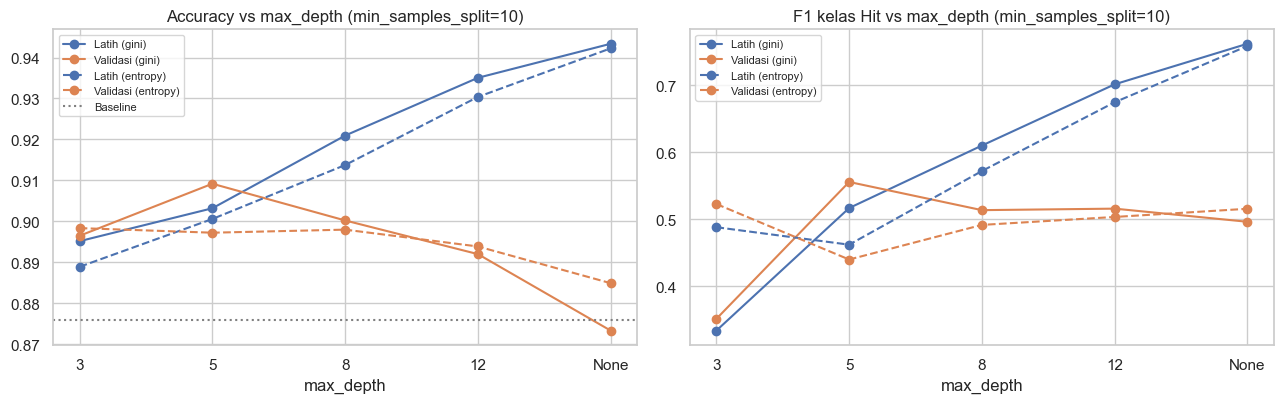

In [35]:
# Kurva akurasi & F1 terhadap kedalaman (min_samples_split=10, tanpa class_weight)
urut_depth = [3, 5, 8, 12, 'None']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for crit, gaya in [('gini', '-'), ('entropy', '--')]:
    sub = hasil_dt[(hasil_dt['criterion'] == crit) & (hasil_dt['min_samples_split'] == 10)
                   & (hasil_dt['class_weight'] == 'None')].set_index('max_depth').loc[urut_depth]
    xs = range(len(urut_depth))
    ax[0].plot(xs, sub['acc_train'], gaya, marker='o', color='#4C72B0', label=f'Latih ({crit})')
    ax[0].plot(xs, sub['acc_val'], gaya, marker='o', color='#DD8452', label=f'Validasi ({crit})')
    ax[1].plot(xs, sub['f1_train'], gaya, marker='o', color='#4C72B0', label=f'Latih ({crit})')
    ax[1].plot(xs, sub['f1_val'], gaya, marker='o', color='#DD8452', label=f'Validasi ({crit})')
ax[0].axhline(1 - y_val.mean(), color='gray', ls=':', label='Baseline')
for a, judul in zip(ax, ['Accuracy', 'F1 kelas Hit']):
    a.set_xticks(range(len(urut_depth)), urut_depth); a.set_xlabel('max_depth')
    a.set_title(f'{judul} vs max_depth (min_samples_split=10)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Analisis kurva:** Garis latih (biru) terus naik seiring kedalaman, dari 0,89 di depth 3 sampai 0,94 di depth None. Garis validasi (oranye) justru memuncak di **depth 5 (0,909, Gini)** lalu turun ke 0,873 di depth None, bahkan di bawah baseline 0,876. Pola ini sesuai hipotesis: depth 3 cenderung *underfitting* (Gini depth 3 F1 hanya 0,351 karena recall rendah), sedangkan depth ≥ 8 mulai *overfitting* (celah latih–validasi melebar). Pada F1 validasi, kurva Entropy tidak serapi Gini (justru turun di depth 5), menandakan hasil satu split validasi masih ber-*variance*; ini akan dicek ulang dengan 5-fold CV di Fase 6.

#### Efek `min_samples_split` dan `max_depth` (heatmap F1 validasi, Gini)

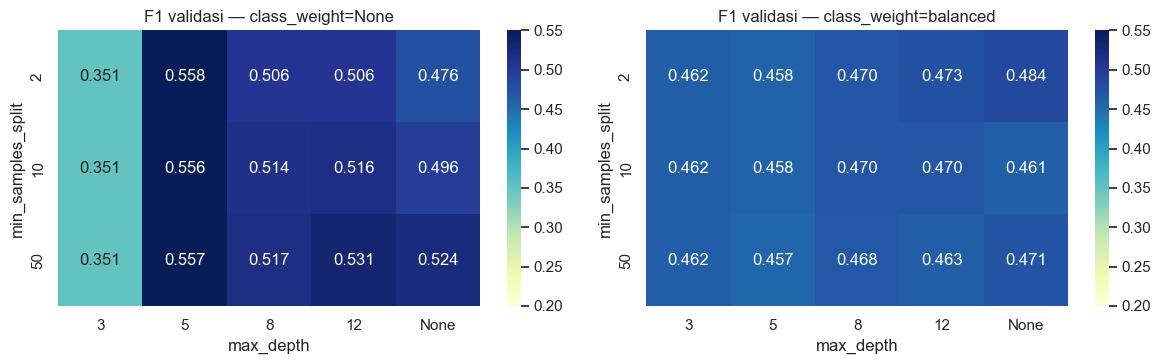

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, cw in zip(ax, ['None', 'balanced']):
    pv = (hasil_dt[(hasil_dt['criterion'] == 'gini') & (hasil_dt['class_weight'] == cw)]
          .pivot(index='min_samples_split', columns='max_depth', values='f1_val')[urut_depth])
    sns.heatmap(pv, annot=True, fmt='.3f', cmap='YlGnBu', ax=a, vmin=0.2, vmax=0.55)
    a.set_title(f'F1 validasi — class_weight={cw}')
plt.tight_layout(); plt.show()

**Analisis heatmap:** Tanpa class_weight (kiri), `min_samples_split` hampir tidak berpengaruh pada pohon dangkal (depth 3–5), karena pohon sudah berhenti oleh `max_depth` sebelum node menjadi kecil. Efeknya baru terlihat pada pohon dalam: di depth None, F1 naik dari **0,476 (mss=2) ke 0,524 (mss=50)**, karena node kecil yang hanya menghafal noise tidak lagi dipecah (pohon Entropy depth None menyusut dari 2.143 menjadi 685 node). Dengan `balanced` (kanan), F1 stabil di kisaran 0,46–0,48 untuk semua kombinasi.

#### Efek `class_weight`

,criterion,max_depth,min_samples_split,class_weight,acc_val,precision_val,recall_val,f1_val
0,gini,5,2,None,0.9095,0.7083,0.4608,0.5584
1,entropy,12,10,balanced,0.8321,0.3975,0.6837,0.5028


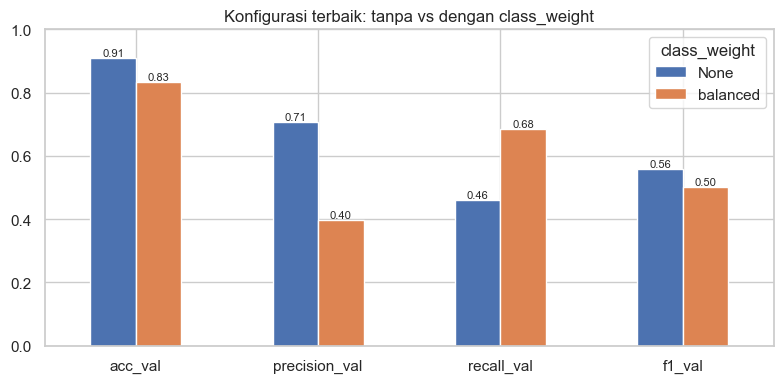

In [37]:
# Bandingkan konfigurasi terbaik tanpa vs dengan class_weight
baris = []
for cw in ['None', 'balanced']:
    terbaik = hasil_dt[hasil_dt['class_weight'] == cw].sort_values('f1_val', ascending=False).iloc[0]
    baris.append(terbaik)
banding = pd.DataFrame(baris)[['criterion', 'max_depth', 'min_samples_split', 'class_weight',
                               'acc_val', 'precision_val', 'recall_val', 'f1_val']].reset_index(drop=True)
display(banding.round(4))

ax = banding.set_index('class_weight')[['acc_val', 'precision_val', 'recall_val', 'f1_val']].T.plot(
    kind='bar', rot=0, figsize=(8, 4), color=['#4C72B0', '#DD8452'])
ax.set_title('Konfigurasi terbaik: tanpa vs dengan class_weight'); ax.set_ylim(0, 1)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

**Analisis class_weight:** Sesuai hipotesis, `balanced` menaikkan **recall Hit dari 0,46 ke 0,68** (lebih banyak game Hit yang tertangkap), tetapi **precision turun dari 0,71 ke 0,40** dan accuracy turun dari 0,910 ke 0,832, karena model jauh lebih sering menebak Hit. F1 akhirnya lebih rendah (0,503 vs 0,558). Pilihan ini bergantung kebutuhan: jika tujuan bisnis adalah *tidak melewatkan* calon game laris, `balanced` lebih cocok; jika prediksi Hit harus bisa dipercaya, tanpa class_weight lebih baik.

#### Gini vs Entropy

In [38]:
# Rata-rata metrik validasi per criterion (semua kombinasi lain dirata-rata)
hasil_dt.groupby(['criterion', 'class_weight'])[['acc_val', 'precision_val', 'recall_val', 'f1_val']].mean().round(4)

acc_val  precision_val  recall_val  f1_val
criterion class_weight                                            
entropy   None           0.8958         0.6261      0.4191  0.4976
          balanced       0.8005         0.3558      0.7183  0.4728
gini      None           0.8963         0.6570      0.4076  0.4874
          balanced       0.7964         0.3481      0.7139  0.4659

**Analisis Gini vs Entropy:** Rata-rata seluruh kombinasi hampir identik: accuracy validasi 0,896 vs 0,896 dan selisih F1 hanya ~0,01. Ini sesuai literatur bahwa kedua ukuran impurity jarang menghasilkan perbedaan besar. Perbedaan muncul pada konfigurasi tertentu (misalnya depth 3: F1 Entropy 0,523 vs Gini 0,351) karena pemilihan split awal yang berbeda kemudian memengaruhi seluruh cabang di bawahnya.

### 4.14 Model Decision Tree terbaik

In [39]:
# Ambil konfigurasi dengan F1 validasi tertinggi, lalu latih ulang di SELURUH data latih
best_dt = hasil_dt.sort_values('f1_val', ascending=False).iloc[0]
DT_PARAMS = dict(criterion=best_dt['criterion'],
                 max_depth=None if best_dt['max_depth'] == 'None' else int(best_dt['max_depth']),
                 min_samples_split=int(best_dt['min_samples_split']),
                 class_weight=None if best_dt['class_weight'] == 'None' else best_dt['class_weight'])
print('Hyperparameter terbaik:', DT_PARAMS)
print(f"Validasi -> accuracy {best_dt['acc_val']:.4f} | precision {best_dt['precision_val']:.4f} | "
      f"recall {best_dt['recall_val']:.4f} | F1 {best_dt['f1_val']:.4f}")

dt_final = DecisionTreeManual(**DT_PARAMS).fit(X_train, y_train)
print(f'Model final: {dt_final.n_nodes} node, kedalaman {dt_final.depth_}')
print('(Evaluasi pada data uji dilakukan di Fase 6)')

Hyperparameter terbaik: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 2, 'class_weight': None}
Validasi -> accuracy 0.9095 | precision 0.7083 | recall 0.4608 | F1 0.5584
Model final: 61 node, kedalaman 5
(Evaluasi pada data uji dilakukan di Fase 6)


In [40]:
# Aturan pohon sampai kedalaman 3
dt_final.print_rules(max_depth=3)

|--- log_User_Count <= 4.20
|   |--- Publisher_Top == Nintendo
|   |   |--- Era == <2000
|   |   |   => Hit  (n=132, p_hit=0.70)
|   |   |--- Era != <2000
|   |   |   => Tidak Hit  (n=303, p_hit=0.31)
|   |--- Publisher_Top != Nintendo
|   |   |--- Critic_Score <= 78.50
|   |   |   => Tidak Hit  (n=10459, p_hit=0.06)
|   |   |--- Critic_Score > 78.50
|   |   |   => Tidak Hit  (n=753, p_hit=0.21)
|--- log_User_Count > 4.20
|   |--- Platform_Group == PC
|   |   |--- log_User_Count <= 7.90
|   |   |   => Tidak Hit  (n=368, p_hit=0.05)
|   |   |--- log_User_Count > 7.90
|   |   |   => Tidak Hit  (n=35, p_hit=0.43)
|   |--- Platform_Group != PC
|   |   |--- log_User_Count <= 5.87
|   |   |   => Tidak Hit  (n=986, p_hit=0.38)
|   |   |--- log_User_Count > 5.87
|   |   |   => Hit  (n=338, p_hit=0.82)


**Interpretasi aturan:** Split pertama (root) adalah `log_User_Count <= 4.20`, setara dengan **sekitar 65 ulasan user**. Game dengan ulasan user > ~350 (`log_User_Count > 5.87`) di platform non-PC punya peluang Hit 82%. Di cabang ulasan sedikit, game **Nintendo era <2000** tetap Hit (70%), cocok dengan temuan Fase 3 tentang era lama. Platform PC hampir selalu diprediksi Tidak Hit (5%) kecuali ulasannya sangat banyak (> ~2.700). Aturan seperti ini mudah dijelaskan ke orang non-teknis, salah satu kelebihan utama Decision Tree.

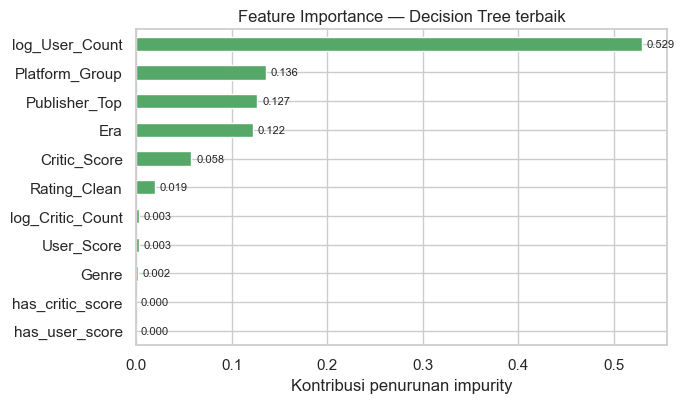

In [41]:
# Fitur paling berpengaruh (total impurity decrease, dinormalisasi)
imp = pd.Series(dt_final.importance_, index=dt_final.features).sort_values()
ax = imp.plot(kind='barh', color='#55A868', figsize=(7, 4.2))
ax.set_title('Feature Importance — Decision Tree terbaik'); ax.set_xlabel('Kontribusi penurunan impurity')
for i, v in enumerate(imp.values):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

**Analisis feature importance:** `log_User_Count` mendominasi (**52,9%**), diikuti `Platform_Group` (13,6%), `Publisher_Top` (12,7%), dan `Era` (12,2%). Hipotesis awal bahwa skor kritikus menjadi fitur teratas **tidak terbukti**: `Critic_Score` hanya 5,8% dan `Genre` 0,2%. Penjelasannya, jumlah ulasan user adalah ukuran *popularitas* yang sangat berkaitan dengan penjualan. **Catatan penting:** jumlah ulasan dikumpulkan *setelah* game rilis, jadi model ini lebih tepat disebut "mengenali game laris dari tingkat keterlibatan pemain" daripada "memprediksi sebelum rilis". Pengaruh fitur ini akan diuji di Fase 6 (eksperimen tanpa fitur jumlah ulasan). `has_critic_score`/`has_user_score` bernilai 0 karena informasinya sudah tercakup oleh `log_*_Count` (bernilai 0 bila tidak ada ulasan).

### 4.15 Ringkasan Fase 4
| Hipotesis (4.11) | Hasil | Status |
|---|---|---|
| 1. Skor/jumlah kritikus jadi fitur teratas | `log_User_Count` paling dominan (52,9%) | ✗ Tidak terbukti |
| 2. depth 3 underfitting | Gini depth 3: acc val 0,896, F1 0,351 (recall rendah) | ✓ Terbukti |
| 3. depth None overfitting | Acc latih 0,973 vs validasi 0,868 | ✓ Terbukti |
| 4. min_samples_split besar meredam overfitting | Depth None: F1 0,476 → 0,524 | ✓ Terbukti (pada pohon dalam) |
| 5. Gini ≈ Entropy | Selisih rata-rata F1 ~0,01 | ✓ Terbukti |
| 6. balanced: recall naik, precision & accuracy turun | Recall 0,46→0,68, precision 0,71→0,40, acc 0,91→0,83 | ✓ Terbukti |

- 60 model dilatih dalam ±15 detik dengan implementasi manual; hitungan contoh 8 data cocok dengan implementasi.
- **Model terbaik:** `criterion=gini, max_depth=5, min_samples_split=2, class_weight=None` → validasi accuracy **0,9095**, F1 **0,558**.
- Model final dilatih ulang pada seluruh data latih (61 node) dan akan diuji di Fase 6.

*Lanjut ke Fase 5: Naive Bayes manual.*

## 5. Naive Bayes (implementasi manual)

### 5.1 Konsep
Naive Bayes adalah klasifikasi probabilistik berdasarkan **Teorema Bayes**:

$$P(C \mid X) = \frac{P(C) \cdot P(X \mid C)}{P(X)}$$

- $P(C)$ = **prior**, peluang kelas sebelum melihat fitur (misal proporsi Hit di data latih).
- $P(X \mid C)$ = **likelihood**, peluang fitur $X$ muncul pada kelas $C$.
- $P(C \mid X)$ = **posterior**, peluang kelas setelah melihat fitur.
- $P(X)$ sama untuk semua kelas, jadi cukup dibandingkan pembilangnya.

**Asumsi "naive"**: semua fitur **saling independen** bila kelasnya diketahui, sehingga likelihood bisa dipecah menjadi perkalian per fitur:

$$P(C \mid x_1, \dots, x_d) \propto P(C) \prod_{i=1}^{d} P(x_i \mid C)$$

Prediksi = kelas dengan posterior terbesar.

### 5.2 Likelihood per jenis fitur
**Fitur kategorikal (Categorical NB + Laplace smoothing):**

$$P(x_i = v \mid C) = \frac{\text{count}(x_i = v, C) + \alpha}{N_C + \alpha \cdot k_i}$$

dengan $N_C$ = jumlah data kelas $C$, $k_i$ = jumlah kategori fitur $i$, $\alpha$ = parameter smoothing. Tanpa smoothing ($\alpha = 0$), satu kategori yang tidak pernah muncul pada suatu kelas membuat seluruh perkalian bernilai 0 (*zero-frequency problem*).

**Fitur numerik (Gaussian NB):** diasumsikan berdistribusi normal di setiap kelas:

$$P(x_i \mid C) = \frac{1}{\sqrt{2\pi\sigma_{C,i}^2}} \exp\left(-\frac{(x_i - \mu_{C,i})^2}{2\sigma_{C,i}^2}\right)$$

dengan $\mu_{C,i}$ dan $\sigma^2_{C,i}$ = rata-rata dan varians fitur $i$ pada kelas $C$ (dihitung dari data latih). Alternatifnya, fitur numerik **di-binning** menjadi kategori (kuantil) lalu diperlakukan sebagai fitur kategorikal.

### 5.3 Log-probability
Perkalian banyak peluang kecil bisa *underflow* menjadi 0 di komputer. Karena itu dipakai penjumlahan logaritma:

$$\log P(C \mid X) \propto \log P(C) + \sum_i \log P(x_i \mid C)$$

Posterior dikembalikan ke skala 0–1 dengan normalisasi *log-sum-exp*.

### 5.4 Contoh hitungan manual (8 data yang sama dengan 4.6)
Prediksi untuk game baru: **Critic_Score = 80, Genre = Shooter**, dengan $\alpha = 1$.

**Prior:** $P(\text{Hit}) = 3/8 = 0{,}375$; $P(\text{Tidak}) = 5/8 = 0{,}625$

**Gaussian untuk Critic_Score:**
- Hit {85, 90, 92}: $\mu = 89$, $\sigma^2 = 8{,}667$ → $P(80 \mid \text{Hit}) = \frac{1}{\sqrt{2\pi \cdot 8{,}667}} e^{-(80-89)^2 / (2 \cdot 8{,}667)} = 0{,}001266$
- Tidak {60, 70, 88, 55, 65}: $\mu = 67{,}6$, $\sigma^2 = 129{,}04$ → $P(80 \mid \text{Tidak}) = 0{,}019355$

**Categorical untuk Genre** (3 kategori: Action, Puzzle, Shooter):
- $P(\text{Shooter} \mid \text{Hit}) = \frac{2 + 1}{3 + 1 \cdot 3} = 0{,}5$
- $P(\text{Shooter} \mid \text{Tidak}) = \frac{1 + 1}{5 + 1 \cdot 3} = 0{,}25$

**Skor (pembilang Bayes):**
- Hit: $0{,}375 \times 0{,}001266 \times 0{,}5 = 0{,}0002374$
- Tidak: $0{,}625 \times 0{,}019355 \times 0{,}25 = 0{,}0030243$

**Posterior:** $P(\text{Hit} \mid X) = \frac{0{,}0002374}{0{,}0002374 + 0{,}0030243} = \mathbf{0{,}0728}$ → prediksi **Tidak Hit**.

Meski genrenya Shooter (lebih sering Hit), skor 80 jauh di bawah rata-rata Hit (89) yang variansnya sangat kecil, sehingga likelihood Gaussian kelas Hit kecil sekali. Ini menunjukkan bagaimana tiap fitur "memberi suara" secara terpisah lalu dikalikan.

### 5.5 Flowchart

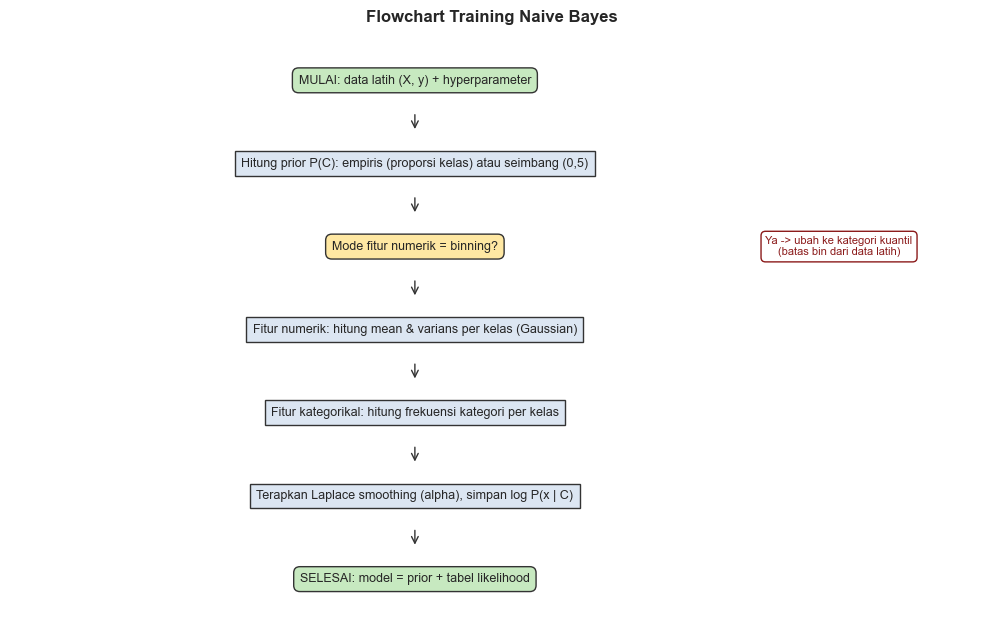

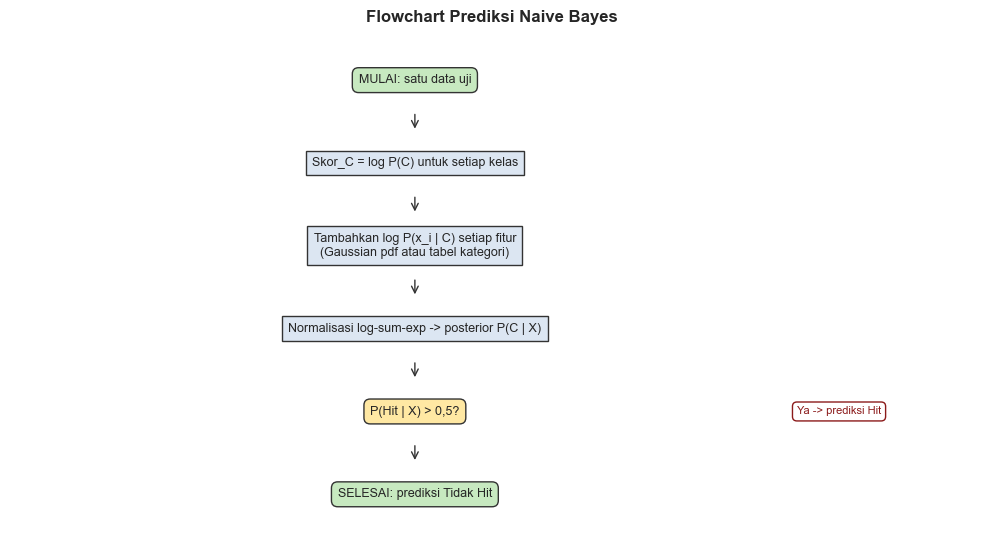

In [42]:
gambar_flowchart([
    ('MULAI: data latih (X, y) + hyperparameter', 'terminal', None),
    ('Hitung prior P(C): empiris (proporsi kelas) atau seimbang (0,5)', 'proses', None),
    ('Mode fitur numerik = binning?', 'keputusan', 'Ya -> ubah ke kategori kuantil\n(batas bin dari data latih)'),
    ('Fitur numerik: hitung mean & varians per kelas (Gaussian)', 'proses', None),
    ('Fitur kategorikal: hitung frekuensi kategori per kelas', 'proses', None),
    ('Terapkan Laplace smoothing (alpha), simpan log P(x | C)', 'proses', None),
    ('SELESAI: model = prior + tabel likelihood', 'terminal', None),
], 'Flowchart Training Naive Bayes')

gambar_flowchart([
    ('MULAI: satu data uji', 'terminal', None),
    ('Skor_C = log P(C) untuk setiap kelas', 'proses', None),
    ('Tambahkan log P(x_i | C) setiap fitur\n(Gaussian pdf atau tabel kategori)', 'proses', None),
    ('Normalisasi log-sum-exp -> posterior P(C | X)', 'proses', None),
    ('P(Hit | X) > 0,5?', 'keputusan', 'Ya -> prediksi Hit'),
    ('SELESAI: prediksi Tidak Hit', 'terminal', None),
], 'Flowchart Prediksi Naive Bayes')

### 5.6 Implementasi

In [43]:
class NaiveBayesManual:
    """Naive Bayes hibrida (Gaussian + Categorical) untuk klasifikasi biner, ditulis dari nol."""

    def __init__(self, alpha=1.0, num_mode='gaussian', prior='empiris', n_bins=5,
                 var_smoothing=1e-9, cat_features=None):
        self.alpha = alpha                  # Laplace smoothing
        self.num_mode = num_mode            # 'gaussian' atau 'binning'
        self.prior = prior                  # 'empiris' atau 'seimbang'
        self.n_bins = n_bins                # jumlah bin kuantil bila num_mode='binning'
        self.var_smoothing = var_smoothing  # tambahan kecil pada varians agar tidak 0
        self.cat_features = cat_features if cat_features is not None else FITUR_KAT

    def _siapkan(self, X):
        """Pisahkan fitur numerik (array) dan kategorikal (DataFrame string), termasuk binning."""
        Xk = X[self.kat].astype(str).copy() if self.kat else pd.DataFrame(index=X.index)
        for f, batas in self.batas_bin.items():
            # nomor bin = jumlah batas dalam yang <= nilai (0 .. n_bins-1)
            Xk[f] = 'bin' + pd.Series(np.searchsorted(batas, X[f].values, side='right'), index=X.index).astype(str)
        Xn = X[self.num].astype(float).values if self.num else np.empty((len(X), 0))
        return Xn, Xk

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        fitur = list(X.columns)
        numerik = [f for f in fitur if f not in self.cat_features]
        self.kat = [f for f in fitur if f in self.cat_features]
        self.batas_bin = {}
        if self.num_mode == 'binning':
            # batas bin = kuantil data latih; batas kembar (misal banyak nilai 0) digabung
            for f in numerik:
                q = np.quantile(X[f].astype(float), np.linspace(0, 1, self.n_bins + 1))[1:-1]
                self.batas_bin[f] = np.unique(q)
            self.num = []
        else:
            self.num = numerik
        Xn, Xk = self._siapkan(X)

        # ---- prior ----
        n_c = np.bincount(y, minlength=2)
        self.log_prior = np.log(n_c / n_c.sum()) if self.prior == 'empiris' else np.log([0.5, 0.5])

        # ---- Gaussian: mean & varians per kelas (ddof=0) ----
        if self.num:
            eps = self.var_smoothing * Xn.var(axis=0).max()
            self.mu = np.array([Xn[y == c].mean(axis=0) for c in (0, 1)])
            self.var = np.array([Xn[y == c].var(axis=0) for c in (0, 1)]) + eps

        # ---- Categorical: tabel log-likelihood per fitur ----
        self.log_lik, self.zero_cells = {}, 0
        for f in Xk.columns:
            tabel = pd.crosstab(Xk[f].values, y).reindex(columns=[0, 1], fill_value=0)   # count(kategori, kelas)
            self.zero_cells += int((tabel.values == 0).sum())
            k = len(tabel)
            with np.errstate(divide='ignore'):                                      # alpha=0 -> log(0) = -inf
                self.log_lik[f] = np.log((tabel + self.alpha) / (n_c + self.alpha * k))
        return self

    def joint_log(self, X):
        """log P(C) + sum log P(x_i | C) untuk setiap data dan kelas -> array (n, 2)."""
        Xn, Xk = self._siapkan(X)
        jl = np.tile(self.log_prior, (len(X), 1))
        if self.num:
            for c in (0, 1):
                jl[:, c] += np.sum(-0.5 * np.log(2 * np.pi * self.var[c])
                                   - (Xn - self.mu[c]) ** 2 / (2 * self.var[c]), axis=1)
        for f, tabel in self.log_lik.items():
            ll = tabel.reindex(Xk[f].values).fillna(0).values   # kategori baru -> diabaikan (log 1 = 0)
            jl += ll
        return jl

    def predict_proba(self, X):
        """Posterior P(Hit | X) dengan normalisasi log-sum-exp."""
        jl = self.joint_log(X)
        m = jl.max(axis=1, keepdims=True)
        with np.errstate(invalid='ignore'):
            p = np.exp(jl - m)
            p1 = p[:, 1] / p.sum(axis=1)
        # jika kedua kelas berpeluang 0 (hanya mungkin bila alpha=0) -> kembali ke prior
        self.n_konflik = int(np.isnan(p1).sum())
        return np.where(np.isnan(p1), np.exp(self.log_prior[1]), p1)

    def predict(self, X):
        return (self.predict_proba(X) > 0.5).astype(int)

### 5.7 Verifikasi dengan contoh hitungan manual

In [44]:
nb_toy = NaiveBayesManual(alpha=1.0, num_mode='gaussian', cat_features=['Genre']).fit(toy, toy_y)
sampel = pd.DataFrame({'Critic_Score': [80], 'Genre': ['Shooter']})

print('Mean Critic_Score (Tidak, Hit)   :', nb_toy.mu[:, 0], '  (manual: 67.6, 89)')
print('Varians Critic_Score (Tidak, Hit):', nb_toy.var[:, 0].round(3), '  (manual: 129.04, 8.667)')
print('P(Shooter | Tidak), P(Shooter | Hit):', np.exp(nb_toy.log_lik['Genre'].loc['Shooter']).values, '  (manual: 0.25, 0.5)')
print('Skor (Tidak, Hit):', np.exp(nb_toy.joint_log(sampel))[0].round(7), '  (manual: 0.0030243, 0.0002374)')
print(f'P(Hit | X) = {nb_toy.predict_proba(sampel)[0]:.4f}   (manual: 0.0728)')
print('Prediksi:', 'Hit' if nb_toy.predict(sampel)[0] else 'Tidak Hit')

Mean Critic_Score (Tidak, Hit)   : [67.6 89. ]   (manual: 67.6, 89)
Varians Critic_Score (Tidak, Hit): [129.04    8.667]   (manual: 129.04, 8.667)
P(Shooter | Tidak), P(Shooter | Hit): [0.25 0.5 ]   (manual: 0.25, 0.5)
Skor (Tidak, Hit): [0.0030243 0.0002374]   (manual: 0.0030243, 0.0002374)
P(Hit | X) = 0.0728   (manual: 0.0728)
Prediksi: Tidak Hit


### 5.8 Output yang diharapkan (hipotesis sebelum eksperimen)
1. **Akurasi NB lebih rendah dari Decision Tree**, karena asumsi independensi dilanggar: `Critic_Score`–`User_Score` berkorelasi 0,58, dan `has_*_score` membawa informasi yang sama dengan `log_*_Count` (bernilai 0 bila tidak ada ulasan), sehingga bukti yang sama "dihitung dua kali".
2. **Mode binning lebih baik dari Gaussian**, karena `log_*_Count` tidak berdistribusi normal (lonjakan besar di 0, lihat Fase 3) dan skor hasil imputasi menumpuk di median.
3. **Pengaruh `alpha` kecil**, karena data latih besar (> 10 ribu baris) dan kategori sudah dirangkum, sehingga hampir tidak ada frekuensi 0.
4. **Prior seimbang** menaikkan recall Hit tetapi menurunkan precision dan accuracy (mirip `class_weight='balanced'` pada DT).
5. **Membuang fitur redundan (`has_*`)** tidak menurunkan, bahkan bisa menaikkan performa.
6. **Training jauh lebih cepat dari Decision Tree** (cukup menghitung frekuensi, rata-rata, varians).

### 5.9 Tabel hyperparameter
| Hyperparameter | Nilai yang diuji | Alasan |
|---|---|---|
| `alpha` (Laplace) | 0, 0,5, 1, 5 | Efek smoothing; 0 = tanpa smoothing |
| `num_mode` | gaussian, binning (5 bin kuantil) | Menguji asumsi distribusi normal fitur numerik |
| `prior` | empiris (12,4% / 87,6%), seimbang (50% / 50%) | Menangani kelas tidak seimbang |
| `fitur` | semua (11), tanpa `has_*` (9) | Menguji efek fitur redundan terhadap asumsi independensi |

Total kombinasi: 4 × 2 × 2 × 2 = **32 model**. Skema validasi dan kriteria pemilihan **sama dengan Fase 4** (data *fit*/*validasi* yang sama, pilih F1 validasi tertinggi) agar perbandingan kedua algoritma adil.

### 5.10 Eksperimen variasi hyperparameter

In [45]:
FITUR_TANPA_HAS = [f for f in FITUR if not f.startswith('has_')]
set_fitur = {'semua': FITUR, 'tanpa has_*': FITUR_TANPA_HAS}

grid_nb = list(product([0, 0.5, 1, 5], ['gaussian', 'binning'], ['empiris', 'seimbang'], set_fitur))
hasil = []
t0 = time.time()
for alpha, mode, prior, nama_fitur in grid_nb:
    kol = set_fitur[nama_fitur]
    t = time.time()
    model = NaiveBayesManual(alpha=alpha, num_mode=mode, prior=prior).fit(X_fit[kol], y_fit)
    waktu = time.time() - t
    m_tr = hitung_metrik(y_fit, model.predict(X_fit[kol]))
    m_va = hitung_metrik(y_val, model.predict(X_val[kol]))
    hasil.append({'alpha': alpha, 'num_mode': mode, 'prior': prior, 'fitur': nama_fitur,
                  'acc_train': m_tr['accuracy'], 'acc_val': m_va['accuracy'],
                  'precision_val': m_va['precision'], 'recall_val': m_va['recall'], 'f1_val': m_va['f1'],
                  'f1_train': m_tr['f1'], 'sel_frekuensi_0': model.zero_cells,
                  'konflik_val': model.n_konflik, 'waktu_fit_s': waktu})
hasil_nb = pd.DataFrame(hasil)
hasil_nb['gap_acc'] = hasil_nb['acc_train'] - hasil_nb['acc_val']
print(f'{len(grid_nb)} model selesai dalam {time.time() - t0:.2f} detik')
print(f"Rata-rata waktu fit NB: {hasil_nb['waktu_fit_s'].mean() * 1000:.1f} ms  |  DT: {hasil_dt['waktu_fit_s'].mean() * 1000:.1f} ms")

32 model selesai dalam 2.88 detik
Rata-rata waktu fit NB: 57.8 ms  |  DT: 220.7 ms


**Catatan waktu:** 32 model Naive Bayes selesai dalam sekitar 3 detik. Rata-rata satu kali training NB sekitar **60 ms**, sedangkan Decision Tree sekitar **210–240 ms** (±4× lebih lambat; angka waktu sedikit berubah setiap kali dijalankan). Training NB hanya menghitung frekuensi, rata-rata, dan varians dalam satu kali lewat data, sedangkan DT harus mengurutkan dan mencoba semua kandidat split di setiap node.

#### Tabel hasil seluruh kombinasi (urut F1 validasi)

In [46]:
kolom_tampil_nb = ['alpha', 'num_mode', 'prior', 'fitur', 'acc_train', 'acc_val', 'gap_acc',
                   'precision_val', 'recall_val', 'f1_val', 'sel_frekuensi_0', 'konflik_val']
hasil_nb.sort_values('f1_val', ascending=False)[kolom_tampil_nb].round(4).reset_index(drop=True)

,alpha,num_mode,prior,fitur,acc_train,acc_val,gap_acc,precision_val,recall_val,f1_val,sel_frekuensi_0,konflik_val
0,0.5,binning,empiris,tanpa has_*,0.8475,0.8658,-0.0183,0.4630,0.5090,0.4849,0,0
1,0.0,binning,empiris,tanpa has_*,0.8477,0.8654,-0.0177,0.4617,0.5090,0.4842,0,0
2,5.0,binning,empiris,tanpa has_*,0.8471,0.8654,-0.0183,0.4617,0.5090,0.4842,0,0
3,1.0,binning,empiris,tanpa has_*,0.8475,0.8654,-0.0180,0.4617,0.5090,0.4842,0,0
4,0.5,gaussian,empiris,tanpa has_*,0.8560,0.8602,-0.0042,0.4397,0.4608,0.4500,0,0
5,1.0,gaussian,empiris,tanpa has_*,0.8561,0.8602,-0.0041,0.4397,0.4608,0.4500,0,0
6,5.0,gaussian,empiris,tanpa has_*,0.8562,0.8598,-0.0037,0.4384,0.4608,0.4493,0,0
7,0.0,gaussian,empiris,tanpa has_*,0.8558,0.8598,-0.0040,0.4384,0.4608,0.4493,0,0
8,0.0,binning,empiris,semua,0.8167,0.8299,-0.0132,0.3727,0.5422,0.4417,0,0
9,0.5,binning,empiris,semua,0.8166,0.8299,-0.0133,0.3727,0.5422,0.4417,0,0


**Analisis tabel:** Konfigurasi terbaik adalah **binning, alpha=0,5, prior empiris, tanpa `has_*`**: accuracy validasi **0,8658** dan F1 **0,485**. Ada tiga pola jelas: (1) semua konfigurasi `tanpa has_*` berada di urutan teratas untuk prior yang sama; (2) prior `seimbang` selalu berada di bagian bawah; (3) baris dengan alpha berbeda tetapi hyperparameter lain sama hasilnya hampir identik. Kolom `sel_frekuensi_0` bernilai 0 untuk semua model, artinya tidak ada kombinasi kategori–kelas yang kosong. Gap latih–validasi semuanya kecil (|gap| < 0,02), jadi NB **tidak overfitting**; masalahnya justru bias model (asumsi terlalu sederhana). **Catatan jujur:** accuracy NB terbaik (0,8658) masih **di bawah baseline 0,876** (tebak "Tidak Hit" semua). Namun baseline punya F1 = 0 karena tidak pernah menemukan game Hit, sedangkan NB menemukan 51% game Hit.

#### Mengapa Gaussian kurang cocok? Distribusi asli vs kurva normal

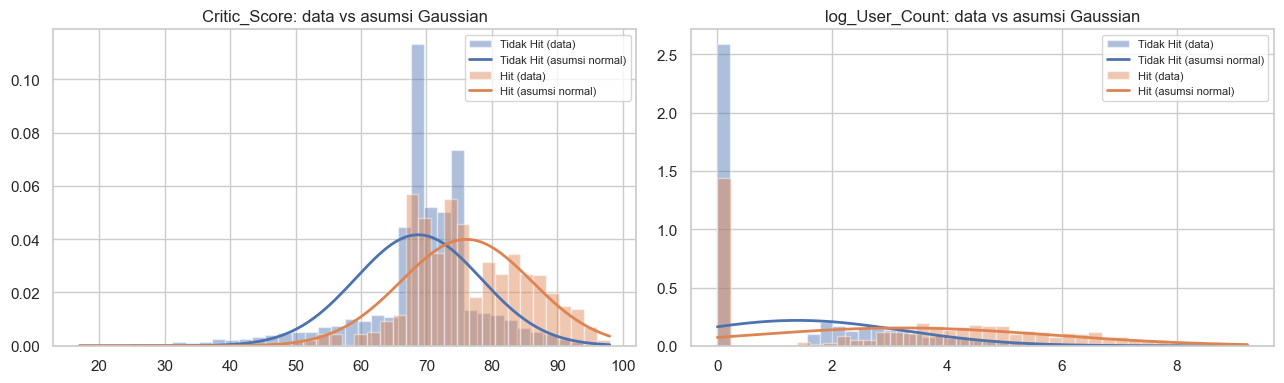

In [47]:
# Bandingkan histogram data asli dengan kurva normal yang diasumsikan Gaussian NB
nb_g = NaiveBayesManual(alpha=1, num_mode='gaussian').fit(X_fit, y_fit)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, f in zip(ax, ['Critic_Score', 'log_User_Count']):
    j = nb_g.num.index(f)
    for c, warna, label in [(0, '#4C72B0', 'Tidak Hit'), (1, '#DD8452', 'Hit')]:
        x = X_fit[f].values[y_fit == c]
        a.hist(x, bins=40, density=True, alpha=0.45, color=warna, label=f'{label} (data)')
        grid_x = np.linspace(X_fit[f].min(), X_fit[f].max(), 300)
        mu, var = nb_g.mu[c, j], nb_g.var[c, j]
        a.plot(grid_x, np.exp(-(grid_x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var),
               color=warna, lw=2, label=f'{label} (asumsi normal)')
    a.set_title(f'{f}: data vs asumsi Gaussian'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Analisis plot:** Ini bukti visual mengapa asumsi Gaussian kurang cocok. Pada `Critic_Score`, data memiliki puncak tajam di sekitar 66–75 (efek imputasi median per genre di Fase 3) yang tidak bisa diwakili kurva normal. Pada `log_User_Count`, sebagian besar data menumpuk di 0 (game tanpa ulasan) dan sisanya menyebar ke kanan, sehingga kurva normal (garis) sama sekali tidak mengikuti histogram. Binning tidak mengasumsikan bentuk distribusi apa pun, jadi lebih fleksibel untuk data seperti ini.

#### Efek `alpha` dan `num_mode`

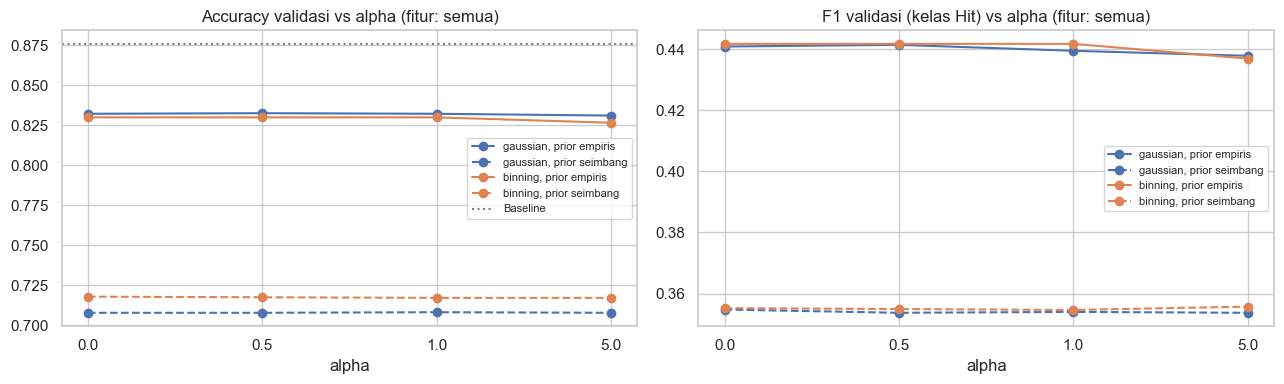

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for mode, warna in [('gaussian', '#4C72B0'), ('binning', '#DD8452')]:
    for prior, gaya in [('empiris', '-'), ('seimbang', '--')]:
        sub = hasil_nb[(hasil_nb['num_mode'] == mode) & (hasil_nb['prior'] == prior)
                       & (hasil_nb['fitur'] == 'semua')].sort_values('alpha')
        lbl = f'{mode}, prior {prior}'
        ax[0].plot(sub['alpha'].astype(str), sub['acc_val'], gaya, marker='o', color=warna, label=lbl)
        ax[1].plot(sub['alpha'].astype(str), sub['f1_val'], gaya, marker='o', color=warna, label=lbl)
ax[0].axhline(1 - y_val.mean(), color='gray', ls=':', label='Baseline')
for a, judul in zip(ax, ['Accuracy validasi', 'F1 validasi (kelas Hit)']):
    a.set_xlabel('alpha'); a.set_title(f'{judul} vs alpha (fitur: semua)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Analisis alpha:** Garis hampir datar: mengubah alpha dari 0 ke 5 hanya menggeser accuracy/F1 di digit ketiga (misal F1 binning-empiris 0,442 → 0,437). Ini sesuai hipotesis 3: data latih besar (10.699 baris) dan kategori sudah dirangkum di Fase 3, sehingga tidak ada frekuensi 0 dan smoothing hampir tidak berperan. Alpha baru akan penting pada data kecil atau kategori yang sangat jarang. Perbedaan besar justru datang dari **prior** (garis putus-putus jauh di bawah garis utuh).

#### Efek `prior` dan `fitur`

In [49]:
# Rata-rata metrik validasi per nilai hyperparameter (kombinasi lain dirata-rata)
for hp in ['num_mode', 'prior', 'fitur']:
    print(hasil_nb.groupby(hp)[['acc_val', 'precision_val', 'recall_val', 'f1_val']].mean().round(4), '\n')

          acc_val  precision_val  recall_val  f1_val
num_mode                                            
binning    0.7903         0.3394      0.5777  0.4163
gaussian   0.7878         0.3358      0.5759  0.4107 

          acc_val  precision_val  recall_val  f1_val
prior                                               
empiris    0.8466         0.4118      0.5109  0.4536
seimbang   0.7314         0.2634      0.6427  0.3733 

             acc_val  precision_val  recall_val  f1_val
fitur                                                  
semua         0.7715         0.3094      0.5866  0.3974
tanpa has_*   0.8065         0.3657      0.5670  0.4296 



**Analisis rata-rata per hyperparameter:**
- **num_mode:** binning sedikit lebih baik dari Gaussian (F1 rata-rata 0,416 vs 0,411); selisih kecil, tetapi konfigurasi terbaik keseluruhan memakai binning. Hipotesis 2 terbukti, namun efeknya tidak sebesar yang diperkirakan.
- **prior:** prior seimbang menaikkan recall (0,51 → 0,64) tetapi precision turun tajam (0,41 → 0,26) dan accuracy turun (0,847 → 0,731). F1 ikut turun (0,454 → 0,373).
- **fitur:** membuang `has_*` menaikkan accuracy (0,772 → 0,807) **dan** F1 (0,397 → 0,430). Ini efek terbesar setelah prior, dan membuktikan masalah *double counting*: NB menganggap `has_user_score=0` dan `log_User_Count=0` sebagai dua bukti terpisah, padahal keduanya informasi yang sama.

,alpha,num_mode,prior,fitur,acc_val,precision_val,recall_val,f1_val
0,0.5,binning,empiris,tanpa has_*,0.8658,0.4630,0.5090,0.4849
1,5.0,gaussian,seimbang,tanpa has_*,0.7529,0.2866,0.6657,0.4007


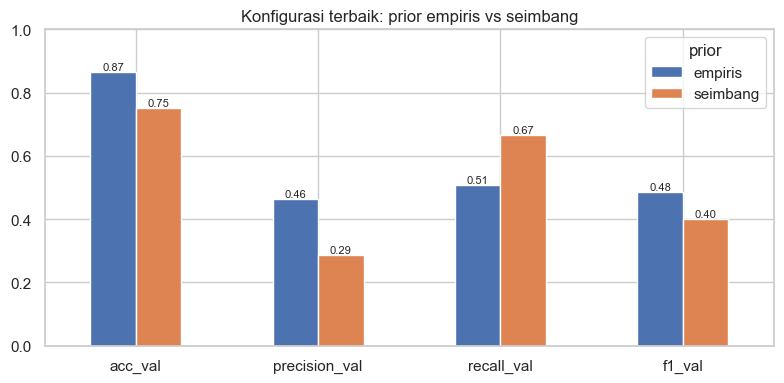

In [50]:
# Konfigurasi terbaik per prior, ditampilkan berdampingan
baris = [hasil_nb[hasil_nb['prior'] == p].sort_values('f1_val', ascending=False).iloc[0] for p in ['empiris', 'seimbang']]
banding_nb = pd.DataFrame(baris)[['alpha', 'num_mode', 'prior', 'fitur', 'acc_val', 'precision_val', 'recall_val', 'f1_val']].reset_index(drop=True)
display(banding_nb.round(4))
ax = banding_nb.set_index('prior')[['acc_val', 'precision_val', 'recall_val', 'f1_val']].T.plot(
    kind='bar', rot=0, figsize=(8, 4), color=['#4C72B0', '#DD8452'])
ax.set_title('Konfigurasi terbaik: prior empiris vs seimbang'); ax.set_ylim(0, 1)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

**Analisis prior:** Dengan prior seimbang, model menganggap peluang awal Hit = 50% (padahal aslinya 12,4%), sehingga jauh lebih sering menebak Hit. Recall naik dari 0,51 ke 0,67, tetapi dari setiap 10 game yang diprediksi Hit, hanya sekitar 3 yang benar (precision 0,29). Efeknya serupa `class_weight='balanced'` pada Decision Tree. Untuk tujuan F1 maupun accuracy, **prior empiris lebih baik**.

### 5.11 Model Naive Bayes terbaik

In [51]:
best_nb = hasil_nb.sort_values('f1_val', ascending=False).iloc[0]
NB_PARAMS = dict(alpha=float(best_nb['alpha']), num_mode=best_nb['num_mode'], prior=best_nb['prior'])
NB_FITUR = set_fitur[best_nb['fitur']]
print('Hyperparameter terbaik:', NB_PARAMS, '| fitur:', best_nb['fitur'])
print(f"Validasi -> accuracy {best_nb['acc_val']:.4f} | precision {best_nb['precision_val']:.4f} | "
      f"recall {best_nb['recall_val']:.4f} | F1 {best_nb['f1_val']:.4f}")

# Latih ulang di SELURUH data latih
nb_final = NaiveBayesManual(**NB_PARAMS).fit(X_train[NB_FITUR], y_train)
print('(Evaluasi pada data uji dilakukan di Fase 6)')

Hyperparameter terbaik:

 {'alpha': 0.5, 'num_mode': 'binning', 'prior': 'empiris'} | fitur: tanpa has_*
Validasi -> accuracy 0.8658 | precision 0.4630 | recall 0.5090 | F1 0.4849
(Evaluasi pada data uji dilakukan di Fase 6)


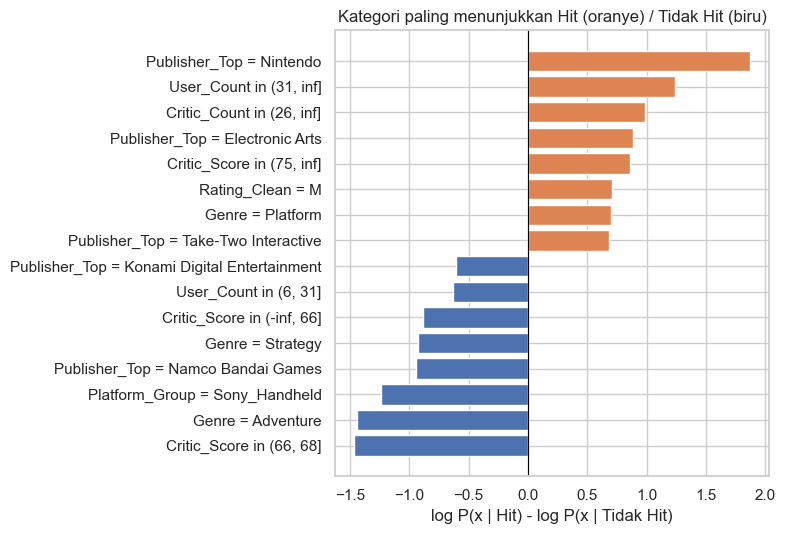

In [52]:
# Interpretasi: kategori yang paling 'mendorong' ke Hit / Tidak Hit
# log-likelihood ratio = log P(kategori | Hit) - log P(kategori | Tidak Hit)
llr = []
for f, tabel in nb_final.log_lik.items():
    for kategori, (l0, l1) in tabel.iterrows():
        llr.append({'fitur': f, 'kategori': kategori, 'LLR': l1 - l0})
llr = pd.DataFrame(llr).sort_values('LLR')
pilih = pd.concat([llr.head(8), llr.tail(8)])
plt.figure(figsize=(8, 5.5))
def label_kategori(f, k):
    """Ubah 'binK' menjadi rentang nilai asli agar mudah dibaca."""
    if f not in nb_final.batas_bin:
        return f'{f} = {k}'
    b = [-np.inf] + list(nb_final.batas_bin[f]) + [np.inf]
    lo, hi = b[int(k[3:])], b[int(k[3:]) + 1]
    if f.startswith('log_'):                     # kembalikan ke jumlah ulasan asli
        f, lo, hi = f[4:], np.expm1(lo), np.expm1(hi)
    lo_s = '-inf' if np.isinf(lo) else f'{lo:.0f}'
    hi_s = 'inf' if np.isinf(hi) else f'{hi:.0f}'
    return f'{f} in ({lo_s}, {hi_s}]'

plt.barh([label_kategori(f, k) for f, k in zip(pilih['fitur'], pilih['kategori'])], pilih['LLR'],
         color=np.where(pilih['LLR'] > 0, '#DD8452', '#4C72B0'))
plt.axvline(0, color='black', lw=0.8)
plt.title('Kategori paling menunjukkan Hit (oranye) / Tidak Hit (biru)')
plt.xlabel('log P(x | Hit) - log P(x | Tidak Hit)')
plt.tight_layout(); plt.show()

**Interpretasi:** Batang oranye menunjukkan kategori yang lebih sering muncul pada game Hit. Publisher **Nintendo** adalah penanda Hit terkuat (LLR ≈ 1,9, artinya kategori ini ±6,5× lebih mungkin muncul pada game Hit dibanding Tidak Hit), disusul ulasan user > 31, ulasan kritikus > 26, publisher Electronic Arts, dan skor kritikus > 75. Penanda Tidak Hit terkuat adalah skor kritikus di rentang **66–68**, genre Adventure, dan platform Sony_Handheld. Rentang 66–68 itu menarik: ini tepat di nilai median imputasi (Fase 3), jadi sebenarnya yang ditangkap model adalah "game yang tidak punya skor asli". Ini menunjukkan informasi `has_critic_score` tetap masuk ke model walaupun kolomnya dibuang.

### 5.12 Ringkasan Fase 5
| Hipotesis (5.8) | Hasil | Status |
|---|---|---|
| 1. Akurasi NB < Decision Tree | NB 0,8658 vs DT 0,9095 (F1 0,485 vs 0,558) | ✓ Terbukti |
| 2. Binning > Gaussian | F1 rata-rata 0,416 vs 0,411, model terbaik memakai binning | ✓ Terbukti (efek kecil) |
| 3. Pengaruh alpha kecil | Tidak ada frekuensi 0; selisih F1 < 0,005 | ✓ Terbukti |
| 4. Prior seimbang: recall naik, precision & accuracy turun | Recall 0,51→0,64, precision 0,41→0,26, acc 0,85→0,73 | ✓ Terbukti |
| 5. Membuang `has_*` tidak menurunkan performa | F1 0,397 → 0,430, acc 0,772 → 0,807 | ✓ Terbukti (malah naik) |
| 6. Training NB lebih cepat | ±60 ms vs ±220 ms per model | ✓ Terbukti |

- Implementasi manual cocok dengan hitungan tangan (posterior contoh = 0,0728).
- **Model terbaik:** `alpha=0.5, num_mode=binning, prior=empiris`, fitur tanpa `has_*` → validasi accuracy **0,8658**, F1 **0,485**.
- Kelemahan utama NB di dataset ini adalah **pelanggaran asumsi independensi** (fitur redundan dan berkorelasi), bukan overfitting.
- Model final dilatih ulang pada seluruh data latih dan akan diuji bersama Decision Tree di Fase 6.

*Lanjut ke Fase 6: Evaluasi & perbandingan.*

## 6. Evaluasi & Perbandingan

### 6.1 Pengukuran performansi yang dipakai
**Confusion matrix** (kelas positif = Hit):

| | Prediksi Hit | Prediksi Tidak Hit |
|---|---|---|
| **Aktual Hit** | TP — game laris yang berhasil dikenali | FN — game laris yang terlewat |
| **Aktual Tidak Hit** | FP — game biasa yang dikira laris | TN — game biasa yang dikenali benar |

| Metrik | Rumus | Arti dalam kasus ini |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Persentase seluruh prediksi yang benar |
| Precision | $\frac{TP}{TP + FP}$ | Dari game yang diprediksi Hit, berapa yang benar-benar Hit |
| Recall | $\frac{TP}{TP + FN}$ | Dari seluruh game Hit, berapa yang berhasil ditemukan |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Rata-rata harmonik precision & recall |

**Mengapa accuracy saja menyesatkan?** Hanya 12,4% game yang Hit. Model "bodoh" yang selalu menebak *Tidak Hit* sudah mendapat accuracy ±87,6% tetapi recall dan F1 = 0, karena tidak pernah menemukan satu pun game laris. Karena itu semua tabel menampilkan **baseline** ini sebagai pembanding, dan F1 kelas Hit dipakai sebagai metrik pendamping.

**Skema evaluasi:**
1. **Hold-out test** — model terbaik dari Fase 4 & 5 (dilatih di seluruh data latih) diuji sekali pada **data uji 20% (3.343 game)** yang belum pernah dipakai sama sekali.
2. **5-fold stratified cross-validation** — seluruh 16.717 data dibagi 5 bagian dengan proporsi Hit yang sama; setiap bagian bergiliran menjadi data uji. Preprocessor di-fit ulang di setiap fold. Hasil dilaporkan sebagai **rata-rata ± standar deviasi** untuk melihat stabilitas.

### 6.2 Hasil pada data uji (hold-out)

In [53]:
# Prediksi kedua model final pada data uji
t = time.time(); pred_dt = dt_final.predict(X_test); waktu_pred_dt = time.time() - t
t = time.time(); pred_nb = nb_final.predict(X_test[NB_FITUR]); waktu_pred_nb = time.time() - t
pred_base = np.zeros_like(y_test)                       # baseline: selalu 'Tidak Hit'

def baris_metrik(nama, y_true, y_pred):
    m = hitung_metrik(y_true, y_pred)
    tp, tn, fp, fn = confusion(y_true, y_pred)
    return {'Model': nama, **m, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

tabel_uji = pd.DataFrame([
    baris_metrik('Baseline (selalu Tidak Hit)', y_test, pred_base),
    baris_metrik('Decision Tree', y_test, pred_dt),
    baris_metrik('Naive Bayes', y_test, pred_nb),
]).set_index('Model')
tabel_uji.round(4)

,accuracy,precision,recall,f1,TP,FP,FN,TN
Model,,,,,,,,
Baseline (selalu Tidak Hit),0.8759,0.0000,0.0000,0.0000,0,0,415,2928
Decision Tree,0.9001,0.6901,0.3542,0.4682,147,66,268,2862
Naive Bayes,0.8561,0.4312,0.4988,0.4626,207,273,208,2655


**Analisis:** Pada 3.343 game di data uji, **Decision Tree mendapat accuracy 0,9001**, satu-satunya model yang mengalahkan baseline (0,8759). **Naive Bayes hanya 0,8561**, di bawah baseline. Namun keduanya jauh lebih berguna dari baseline yang tidak menemukan satu pun game Hit. Kedua model punya "gaya" berbeda: DT **hati-hati** (hanya 213 prediksi Hit, 69% benar, tetapi 268 game Hit terlewat), sedangkan NB **agresif** (480 prediksi Hit, 43% benar, menemukan 207 dari 415 game Hit). F1 keduanya hampir sama (0,468 vs 0,463). F1 DT di data uji lebih rendah dari F1 validasi Fase 4 (0,558); ini wajar karena konfigurasi dipilih dari skor validasi tertinggi sehingga skor validasi cenderung terlalu optimis. Data uji memberi angka yang lebih jujur.

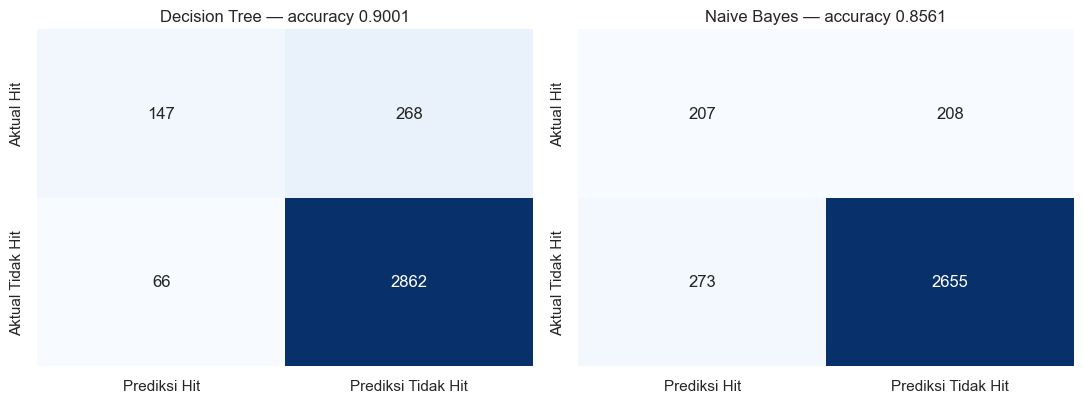

In [54]:
# Confusion matrix kedua model (data uji)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (nama, pred) in zip(ax, [('Decision Tree', pred_dt), ('Naive Bayes', pred_nb)]):
    tp, tn, fp, fn = confusion(y_test, pred)
    cm = np.array([[tp, fn], [fp, tn]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Prediksi Hit', 'Prediksi Tidak Hit'], yticklabels=['Aktual Hit', 'Aktual Tidak Hit'])
    a.set_title(f'{nama} — accuracy {hitung_metrik(y_test, pred)["accuracy"]:.4f}')
plt.tight_layout(); plt.show()

**Analisis confusion matrix:** Kesalahan terbesar DT adalah **False Negative (268)**: lebih dari separuh game Hit tidak dikenali. Kesalahan terbesar NB adalah **False Positive (273)**: banyak game biasa dikira laris. Perbedaan ini sesuai dengan sifat keduanya: DT dangkal (depth 5) hanya menandai Hit di leaf yang mayoritasnya Hit, sedangkan NB menjumlahkan "suara" banyak fitur sehingga game dengan beberapa ciri positif (misal publisher besar + skor tinggi) mudah terdorong ke Hit.

### 6.3 5-fold stratified cross-validation

In [55]:
def stratified_kfold(y, k=5, seed=SEED):
    """Membagi indeks menjadi k fold dengan proporsi kelas yang sama (manual)."""
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for kelas in np.unique(y):
        idx = np.where(y == kelas)[0]
        rng.shuffle(idx)
        for i, potongan in enumerate(np.array_split(idx, k)):   # bagi rata ke k fold
            folds[i].extend(potongan)
    return [np.array(sorted(f)) for f in folds]

FITUR_PRA = [f for f in FITUR if f not in ('log_Critic_Count', 'log_User_Count')]   # tanpa jumlah ulasan
skenario = {
    'lengkap':             {'DT': FITUR, 'NB': NB_FITUR},
    'tanpa jumlah ulasan': {'DT': FITUR_PRA, 'NB': [f for f in NB_FITUR if f in FITUR_PRA]},
}

folds = stratified_kfold(data['Hit'].values, k=5)
hasil_cv = []
for i, idx_te_cv in enumerate(folds):
    idx_tr_cv = np.setdiff1d(np.arange(len(data)), idx_te_cv)
    pp = Preprocessor().fit(data.iloc[idx_tr_cv])                       # fit hanya di fold latih
    tr_cv, te_cv = pp.transform(data.iloc[idx_tr_cv]), pp.transform(data.iloc[idx_te_cv])
    ytr, yte = tr_cv[TARGET].values, te_cv[TARGET].values
    hasil_cv.append({'skenario': 'lengkap', 'model': 'Baseline', 'fold': i + 1,
                     **hitung_metrik(yte, np.zeros_like(yte))})
    for nama_sk, fitur_sk in skenario.items():
        for nama_model in ['DT', 'NB']:
            kol = fitur_sk[nama_model]
            t = time.time()
            if nama_model == 'DT':
                model = DecisionTreeManual(**DT_PARAMS).fit(tr_cv[kol], ytr)
            else:
                model = NaiveBayesManual(**NB_PARAMS).fit(tr_cv[kol], ytr)
            waktu = time.time() - t
            m_tr = hitung_metrik(ytr, model.predict(tr_cv[kol]))
            hasil_cv.append({'skenario': nama_sk, 'model': nama_model, 'fold': i + 1,
                             **hitung_metrik(yte, model.predict(te_cv[kol])),
                             'acc_train': m_tr['accuracy'], 'waktu_fit_s': waktu})
hasil_cv = pd.DataFrame(hasil_cv)
print('Jumlah data per fold:', [len(f) for f in folds])
print('Hit (%) per fold   :', [round(data['Hit'].values[f].mean() * 100, 2) for f in folds])

Jumlah data per fold: [3344, 3344, 3343, 3343, 3343]
Hit (%) per fold   : [np.float64(12.41), np.float64(12.41), np.float64(12.41), np.float64(12.41), np.float64(12.41)]


In [56]:
# Ringkasan CV: rata-rata ± standar deviasi (skenario lengkap)
metrik = ['accuracy', 'precision', 'recall', 'f1']
cv_lengkap = hasil_cv[hasil_cv['skenario'] == 'lengkap']
ringkas = cv_lengkap.groupby('model')[metrik].agg(['mean', 'std'])
tabel_cv = pd.DataFrame({m: ringkas[(m, 'mean')].map('{:.4f}'.format) + ' ± ' + ringkas[(m, 'std')].map('{:.4f}'.format)
                         for m in metrik}).loc[['Baseline', 'DT', 'NB']]
tabel_cv.index = ['Baseline (selalu Tidak Hit)', 'Decision Tree', 'Naive Bayes']
tabel_cv

,accuracy,precision,recall,f1
Baseline (selalu Tidak Hit),0.8759 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Decision Tree,0.8985 ± 0.0017,0.6666 ± 0.0290,0.3687 ± 0.0240,0.4738 ± 0.0120
Naive Bayes,0.8537 ± 0.0044,0.4220 ± 0.0118,0.4814 ± 0.0163,0.4496 ± 0.0088


**Analisis CV:** Hasil 5-fold konsisten dengan data uji: DT accuracy **0,8985 ± 0,0017** vs NB **0,8537 ± 0,0044**, dan F1 DT 0,4738 ± 0,0120 vs NB 0,4496 ± 0,0088. Standar deviasi sangat kecil (< 0,005 untuk accuracy), artinya hasil **stabil** dan tidak bergantung pada cara data dibagi. Selisih accuracy kedua model (±0,045) sekitar 10× lebih besar dari standar deviasinya, jadi keunggulan DT bukan kebetulan.

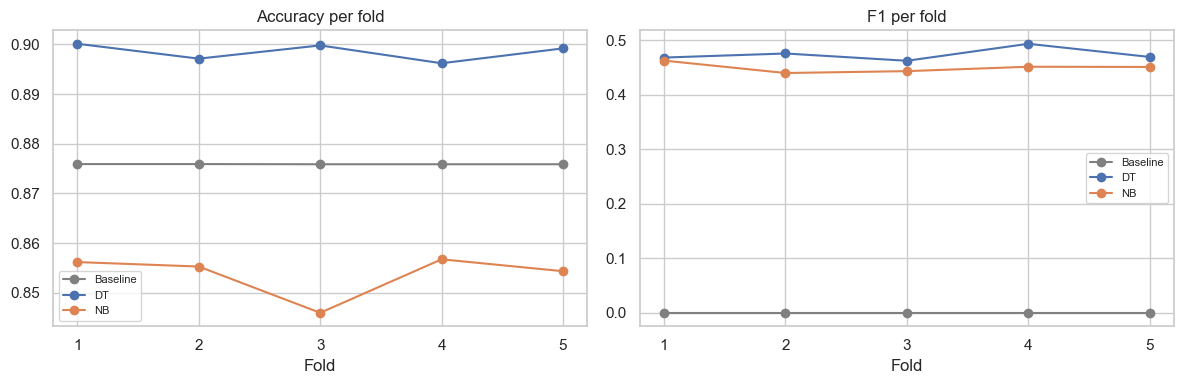

In [57]:
# Accuracy & F1 per fold
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, m in zip(ax, ['accuracy', 'f1']):
    for nama, warna in [('Baseline', 'gray'), ('DT', '#4C72B0'), ('NB', '#DD8452')]:
        sub = cv_lengkap[cv_lengkap['model'] == nama]
        a.plot(sub['fold'], sub[m], marker='o', color=warna, label=nama)
    a.set_xticks(range(1, 6)); a.set_xlabel('Fold'); a.set_title(f'{m.capitalize()} per fold'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Analisis per fold:** Di **kelima fold**, DT selalu di atas baseline dan NB selalu di bawah baseline untuk accuracy. Untuk F1, DT juga unggul di setiap fold, tetapi jaraknya tipis (sekitar 0,005–0,04). Fold 3 adalah fold tersulit untuk NB (accuracy 0,846), sedangkan DT hampir tidak terpengaruh.

### 6.4 Analisis mendalam

#### a. Latih vs uji: apakah ada overfitting?

In [58]:
lt = []
for nama, model, kol in [('Decision Tree', dt_final, FITUR), ('Naive Bayes', nb_final, NB_FITUR)]:
    a_tr = hitung_metrik(y_train, model.predict(X_train[kol]))['accuracy']
    a_te = hitung_metrik(y_test, model.predict(X_test[kol]))['accuracy']
    cv_tr = cv_lengkap[cv_lengkap['model'] == ('DT' if nama == 'Decision Tree' else 'NB')]
    lt.append({'Model': nama, 'Acc latih': a_tr, 'Acc uji': a_te, 'Gap (latih - uji)': a_tr - a_te,
               'Gap rata-rata CV': (cv_tr['acc_train'] - cv_tr['accuracy']).mean()})
pd.DataFrame(lt).set_index('Model').round(4)

,Acc latih,Acc uji,Gap (latih - uji),Gap rata-rata CV
Model,,,,
Decision Tree,0.9034,0.9001,0.0033,0.0067
Naive Bayes,0.8522,0.8561,-0.0039,-0.0000


**Analisis overfitting:** Gap accuracy latih–uji kedua model sangat kecil (DT 0,0033, NB −0,0039), dan rata-rata gap di CV juga < 0,01. **Tidak ada overfitting.** Pembatasan `max_depth=5` berhasil mencegah DT menghafal data (bandingkan dengan pohon tanpa batas di Fase 4 yang gap-nya ±0,09). Keterbatasan kedua model justru *underfitting*: fitur yang tersedia tidak cukup untuk memisahkan Hit dengan sempurna.

#### b. Apakah perbedaan kedua model signifikan? (uji McNemar, manual)

In [59]:
import math

benar_dt, benar_nb = pred_dt == y_test, pred_nb == y_test
b = int((benar_dt & ~benar_nb).sum())     # DT benar, NB salah
c = int((~benar_dt & benar_nb).sum())     # DT salah, NB benar
print(pd.DataFrame([[int((benar_dt & benar_nb).sum()), b], [c, int((~benar_dt & ~benar_nb).sum())]],
                   index=['DT benar', 'DT salah'], columns=['NB benar', 'NB salah']))

# Statistik McNemar dengan koreksi kontinuitas: chi2 = (|b - c| - 1)^2 / (b + c), derajat bebas 1
chi2 = (abs(b - c) - 1) ** 2 / (b + c)
p_value = math.erfc(math.sqrt(chi2 / 2))  # P(chi2_1 > x) = erfc(sqrt(x/2))
print(f'\nb = {b}, c = {c}, chi2 = {chi2:.2f}, p-value = {p_value:.2e}')
print('Kesimpulan:', 'perbedaan SIGNIFIKAN (p < 0,05)' if p_value < 0.05 else 'perbedaan TIDAK signifikan')

          NB benar  NB salah
DT benar      2745       264
DT salah       117       217

b = 264, c = 117, chi2 = 55.95, p-value = 7.44e-14
Kesimpulan: perbedaan SIGNIFIKAN (p < 0,05)


**Analisis signifikansi:** Kedua model sama-sama benar pada 2.745 game dan sama-sama salah pada 217 game. Pada game yang hasilnya berbeda, DT benar sementara NB salah sebanyak **264 kali**, sedangkan kebalikannya hanya **117 kali**. Uji McNemar (dihitung manual) memberi χ² = 55,95 dan **p-value ≈ 7,4 × 10⁻¹⁴**, jauh di bawah 0,05. Jadi perbedaan accuracy DT dan NB **signifikan secara statistik**, bukan kebetulan pembagian data. Ada 217 game yang salah di kedua model; ini kasus yang memang sulit bagi fitur yang tersedia.

#### c. Error analysis: game apa yang salah diprediksi?

In [60]:
# Gabungkan prediksi dengan informasi asli game di data uji
ea = test[['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'Global_Sales',
           'Critic_Score', 'User_Count']].copy()
ea['Hit'] = y_test
ea['pred_DT'], ea['pred_NB'] = pred_dt, pred_nb
ea['p_hit_DT'] = dt_final.predict_proba(X_test)

def jenis(y, p):
    return np.select([(y == 1) & (p == 1), (y == 0) & (p == 0), (y == 0) & (p == 1)], ['TP', 'TN', 'FP'], 'FN')
ea['hasil_DT'] = jenis(ea['Hit'].values, ea['pred_DT'].values)

# Profil tiap jenis hasil DT: berapa persen yang punya ulasan user?
profil = ea.groupby('hasil_DT').agg(jumlah=('Hit', 'size'),
                                    punya_ulasan_user_pct=('User_Count', lambda s: s.notna().mean() * 100),
                                    median_sales=('Global_Sales', 'median'),
                                    median_critic=('Critic_Score', 'median')).round(2)
profil

,jumlah,punya_ulasan_user_pct,median_sales,median_critic
hasil_DT,,,,
FN,268,61.19,1.52,76.0
FP,66,84.85,0.56,84.0
TN,2862,40.95,0.13,68.0
TP,147,78.91,2.19,86.0


**Analisis profil error:** Game yang berhasil dikenali sebagai Hit (TP) mayoritas punya ulasan user (78,9%) dan skor kritikus tinggi (median 86). Game Hit yang **terlewat** (FN) lebih jarang punya ulasan (61,2%) dan skornya lebih rendah (median 76). Sebaliknya game yang **salah dikira Hit** (FP) justru paling banyak punya ulasan (84,8%) dan skornya tinggi (median 84) walaupun penjualannya hanya 0,56 juta. Kesimpulannya, DT sangat bergantung pada "banyak diulas & dinilai bagus", sehingga gagal pada game laris yang jarang diulas dan pada game populer yang penjualannya tidak tercatat.

In [61]:
print('False Negative DT terbesar (game laris yang terlewat):')
display(ea[ea['hasil_DT'] == 'FN'].sort_values('Global_Sales', ascending=False).head(8)
        [['Name', 'Platform', 'Year_of_Release', 'Genre', 'Global_Sales', 'Critic_Score', 'User_Count', 'p_hit_DT']])
print('False Positive DT paling yakin (dikira laris, ternyata tidak):')
display(ea[ea['hasil_DT'] == 'FP'].sort_values('p_hit_DT', ascending=False).head(8)
        [['Name', 'Platform', 'Year_of_Release', 'Genre', 'Global_Sales', 'Critic_Score', 'User_Count', 'p_hit_DT']])

False Negative DT terbesar (game laris yang terlewat):


,Name,Platform,Year_of_Release,Genre,Global_Sales,Critic_Score,User_Count,p_hit_DT
2,Brain Age: Train Your Brain in Minutes a Day,DS,2005.0,Misc,20.15,77.0,50.0,0.454545
6,Pokemon X/Pokemon Y,3DS,2013.0,Role-Playing,14.60,NaN,NaN,0.337580
9,Pokemon Omega Ruby/Pokemon Alpha Sapphire,3DS,2014.0,Role-Playing,11.68,NaN,NaN,0.337580
14,Just Dance 3,Wii,2011.0,Misc,10.12,74.0,16.0,0.037032
18,Mario Party DS,DS,2007.0,Misc,8.91,72.0,85.0,0.443089
20,Wii Party,Wii,2010.0,Misc,8.38,68.0,54.0,0.454545
21,Pokemon Black 2/Pokemon White 2,DS,2012.0,Role-Playing,8.07,NaN,NaN,0.337580
29,Just Dance 4,Wii,2012.0,Misc,6.76,74.0,28.0,0.109331


False Positive DT paling yakin (dikira laris, ternyata tidak):


,Name,Platform,Year_of_Release,Genre,Global_Sales,Critic_Score,User_Count,p_hit_DT
558,The Witcher 3: Wild Hunt,PC,2015.0,Role-Playing,0.72,93.0,10665.0,1.0
490,Killer Instinct Gold,N64,1996.0,Fighting,0.82,NaN,NaN,1.0
2238,Counter-Strike: Source,PC,2004.0,Shooter,0.08,88.0,9851.0,1.0
1668,Street Fighter Alpha 2,SNES,1996.0,Fighting,0.17,NaN,NaN,1.0
1120,Mario Golf,GB,1999.0,Action,0.31,NaN,NaN,0.9
1046,Stunt Race FX,SNES,1993.0,Racing,0.35,NaN,NaN,0.9
626,Cruis'n World,N64,1998.0,Racing,0.64,NaN,NaN,0.9
705,The Mysterious Murasame Castle,NES,1986.0,Action,0.57,NaN,NaN,0.9


**Analisis contoh:** Dua pola kesalahan terlihat jelas:
- **FN didominasi game kasual/keluarga Nintendo** (Brain Age 20,2 juta, Just Dance, Wii Party, Mario Party DS) dan seri **Pokémon** yang tidak punya data Metacritic. Game seperti ini laku keras di pasar umum, tetapi jarang diulas oleh komunitas pengulas sehingga `User_Count` rendah atau kosong.
- **FP paling yakin adalah game PC populer** seperti *The Witcher 3* (10.665 ulasan user) dan *Counter-Strike: Source*. Game ini sebenarnya sangat laris, tetapi dataset (VGChartz) hanya mencatat **penjualan fisik di toko**; penjualan digital (Steam) tidak terhitung, sehingga labelnya "Tidak Hit". Ini **keterbatasan label dataset**, bukan murni kesalahan model. FP lainnya adalah game Nintendo era <2000 (N64/SNES/GB) yang terkena aturan "Nintendo + era lama" dari pohon.

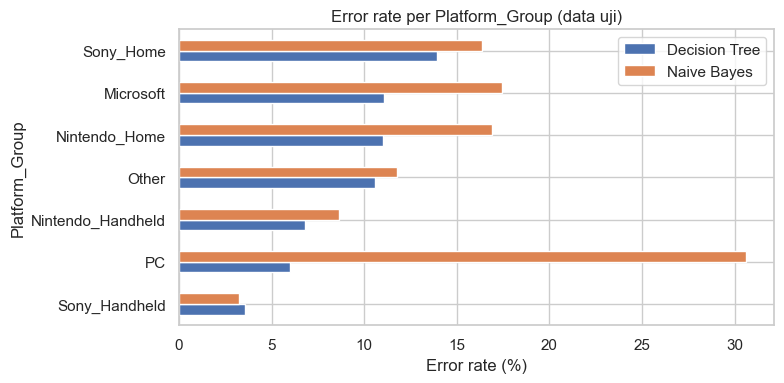

In [62]:
# Tingkat kesalahan per kelompok platform (data uji)
ea['salah_DT'] = ea['pred_DT'] != ea['Hit']
ea['salah_NB'] = ea['pred_NB'] != ea['Hit']
ea['Platform_Group'] = test_p['Platform_Group'].values
err = ea.groupby('Platform_Group')[['salah_DT', 'salah_NB']].mean().mul(100).sort_values('salah_DT')
ax = err.plot(kind='barh', figsize=(8, 4), color=['#4C72B0', '#DD8452'])
ax.set_xlabel('Error rate (%)'); ax.set_title('Error rate per Platform_Group (data uji)')
ax.legend(['Decision Tree', 'Naive Bayes'])
plt.tight_layout(); plt.show()

**Analisis per platform:** Error NB paling parah di **PC (30,6%)**, lima kali lipat error DT (6,0%). Penyebabnya sama dengan contoh FP di atas: game PC sering punya ulasan sangat banyak dan skor tinggi, sehingga NB "mengumpulkan suara" Hit, padahal penjualan fisiknya kecil. DT lebih aman karena punya cabang khusus `Platform_Group == PC` yang menahan prediksi Hit kecuali ulasannya sangat banyak (Fase 4). Pada konsol rumahan (Sony_Home, Microsoft, Nintendo_Home), kedua model punya error tertinggi karena di sanalah game Hit dan Tidak Hit paling bercampur. Platform genggam Sony justru error-nya terendah karena hampir semua game-nya Tidak Hit.

#### d. Pengaruh fitur jumlah ulasan (ablation)

accuracy  precision  recall      f1
model skenario                                                
DT    lengkap                0.8985     0.6666  0.3687  0.4738
      tanpa jumlah ulasan    0.8883     0.6160  0.2684  0.3735
NB    lengkap                0.8537     0.4220  0.4814  0.4496
      tanpa jumlah ulasan    0.8698     0.4629  0.2848  0.3520

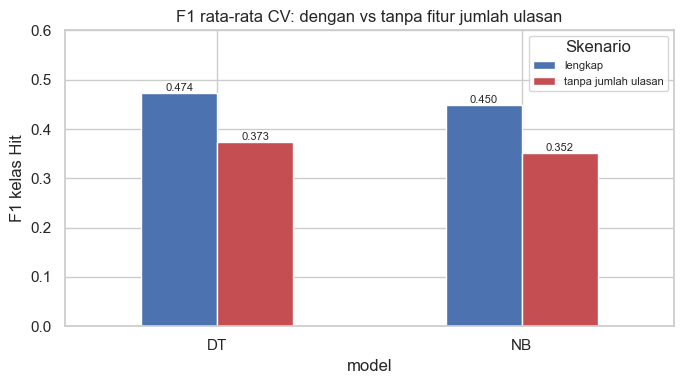

In [63]:
# Bandingkan skenario lengkap vs tanpa jumlah ulasan (rata-rata 5-fold CV)
abl = hasil_cv[hasil_cv['model'] != 'Baseline'].groupby(['model', 'skenario'])[metrik].mean().round(4)
display(abl)

ax = abl['f1'].unstack().plot(kind='bar', rot=0, figsize=(7, 4), color=['#4C72B0', '#C44E52'])
ax.set_title('F1 rata-rata CV: dengan vs tanpa fitur jumlah ulasan'); ax.set_ylabel('F1 kelas Hit')
ax.set_ylim(0, 0.6); ax.legend(title='Skenario', loc='upper right', fontsize=8)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

**Analisis ablation:** Tanpa `log_Critic_Count` dan `log_User_Count`, F1 **DT turun 0,474 → 0,374** dan **NB turun 0,450 → 0,352**; recall kedua model anjlok (DT 0,37 → 0,27, NB 0,48 → 0,28). Ini mengonfirmasi bahwa jumlah ulasan adalah sinyal terkuat, dan sebagian kemampuan model memang berasal dari informasi *setelah* rilis (popularitas). Menariknya, accuracy NB **naik** (0,854 → 0,870) karena tanpa fitur itu NB jauh lebih jarang menebak Hit, sehingga FP berkurang; ini contoh lagi mengapa accuracy saja menyesatkan. Untuk skenario "prediksi sebelum rilis", model hanya mencapai F1 ±0,37, dan ini angka yang realistis untuk dilaporkan.

#### e. Waktu komputasi

In [64]:
t = time.time(); DecisionTreeManual(**DT_PARAMS).fit(X_train, y_train); fit_dt = time.time() - t
t = time.time(); NaiveBayesManual(**NB_PARAMS).fit(X_train[NB_FITUR], y_train); fit_nb = time.time() - t
pd.DataFrame({'Training (detik)': [fit_dt, fit_nb],
              'Prediksi 3.343 data uji (detik)': [waktu_pred_dt, waktu_pred_nb]},
             index=['Decision Tree', 'Naive Bayes']).round(4)

,Training (detik),Prediksi 3.343 data uji (detik)
Decision Tree,0.0659,0.0063
Naive Bayes,0.0792,0.0129


**Analisis waktu:** Dengan konfigurasi final, keduanya sangat cepat: training < 0,1 detik dan prediksi 3.343 game < 0,02 detik. Waktunya hampir sama karena DT terbaik dangkal (depth 5, 61 node). Di Fase 5, NB rata-rata ±4× lebih cepat karena rata-rata itu mencakup pohon tanpa batas kedalaman yang lambat. Untuk dataset sebesar ini, waktu komputasi bukan faktor penentu pemilihan algoritma.

### 6.5 Perbandingan akhir

,Accuracy uji,Accuracy CV (mean),Precision uji,Recall uji,F1 uji,F1 CV (mean)
Model,,,,,,
Baseline (selalu Tidak Hit),0.8759,0.8759,0.0000,0.0000,0.0000,0.0000
Decision Tree,0.9001,0.8985,0.6901,0.3542,0.4682,0.4738
Naive Bayes,0.8561,0.8537,0.4312,0.4988,0.4626,0.4496


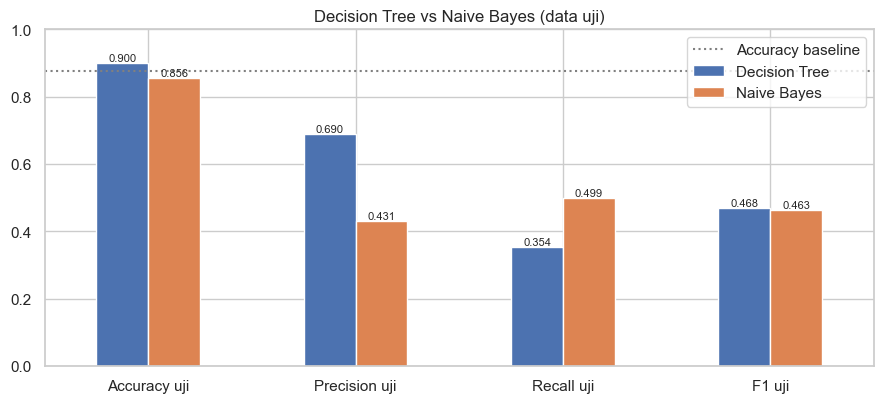

In [65]:
# Tabel ringkas: data uji + CV
akhir = pd.DataFrame({
    'Accuracy uji': tabel_uji['accuracy'],
    'Accuracy CV (mean)': [cv_lengkap[cv_lengkap['model'] == m]['accuracy'].mean() for m in ['Baseline', 'DT', 'NB']],
    'Precision uji': tabel_uji['precision'],
    'Recall uji': tabel_uji['recall'],
    'F1 uji': tabel_uji['f1'],
    'F1 CV (mean)': [cv_lengkap[cv_lengkap['model'] == m]['f1'].mean() for m in ['Baseline', 'DT', 'NB']],
})
display(akhir.round(4))

ax = akhir.loc[['Decision Tree', 'Naive Bayes'], ['Accuracy uji', 'Precision uji', 'Recall uji', 'F1 uji']].T.plot(
    kind='bar', rot=0, figsize=(9, 4.2), color=['#4C72B0', '#DD8452'])
ax.axhline(akhir.loc['Baseline (selalu Tidak Hit)', 'Accuracy uji'], color='gray', ls=':', label='Accuracy baseline')
ax.set_ylim(0, 1); ax.set_title('Decision Tree vs Naive Bayes (data uji)'); ax.legend()
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

### 6.6 Kesimpulan perbandingan

**Algoritma mana yang akurasinya lebih baik? → Decision Tree.**

| | Decision Tree | Naive Bayes |
|---|---|---|
| Accuracy data uji | **0,9001** | 0,8561 |
| Accuracy 5-fold CV | **0,8985 ± 0,0017** | 0,8537 ± 0,0044 |
| Dibanding baseline (0,8759) | +2,4 poin, di atas baseline | −2,0 poin, di bawah baseline |
| F1 data uji / CV | **0,468 / 0,474** | 0,463 / 0,450 |
| Precision / Recall uji | **0,690** / 0,354 | 0,431 / **0,499** |
| Signifikansi (McNemar) | p ≈ 7,4 × 10⁻¹⁴ → beda signifikan | |

Decision Tree unggul **4,4 poin accuracy** di data uji, konsisten di semua fold CV, dan perbedaannya signifikan secara statistik. Untuk F1, DT juga sedikit lebih baik, tetapi selisihnya kecil (0,005 di data uji, 0,024 di CV).

**Mengapa Decision Tree lebih baik pada dataset ini?**
1. **Tidak butuh asumsi independensi.** Banyak fitur saling berkaitan (skor kritikus–user, jumlah ulasan–keberadaan skor). DT memilih satu fitur per split, sedangkan NB menghitung bukti yang sama berkali-kali.
2. **Bisa menangkap interaksi fitur**, misalnya "PC **dan** ulasan sangat banyak" atau "Nintendo **dan** era <2000". NB hanya menjumlahkan pengaruh tiap fitur secara terpisah, sehingga gagal di PC (error 30,6%).
3. **Tidak butuh asumsi bentuk distribusi**; NB Gaussian tidak cocok dengan data yang menumpuk di 0 atau di nilai imputasi.

**Kelebihan & kekurangan di dataset ini**
| | Decision Tree | Naive Bayes |
|---|---|---|
| Kelebihan | Accuracy & precision tertinggi; aturan mudah dibaca; tahan fitur berkorelasi | Recall lebih tinggi (menemukan lebih banyak game Hit); sederhana; sangat cepat; tidak overfitting |
| Kekurangan | Recall rendah (64% game Hit terlewat); rawan overfitting bila kedalaman tidak dibatasi | Asumsi independensi dilanggar; accuracy di bawah baseline; banyak false positive (terutama PC) |

**Rekomendasi:** pilih **Decision Tree** bila prediksi "Hit" harus bisa dipercaya (misal menentukan game yang diberi anggaran promosi besar). Pilih **Naive Bayes** (atau DT dengan `class_weight='balanced'`) bila yang penting adalah **tidak melewatkan** calon game laris, dengan konsekuensi lebih banyak alarm palsu.

**Keterbatasan & saran pengembangan**
- Label hanya berdasarkan **penjualan fisik** (VGChartz), sehingga game PC/digital yang laris tercatat "Tidak Hit".
- Fitur terkuat (jumlah ulasan) baru tersedia **setelah rilis**; tanpa fitur itu F1 turun ke ±0,37.
- Pengembangan: menambah fitur pra-rilis (anggaran, franchise/sekuel, jumlah platform rilis), mencoba *threshold tuning* untuk menyeimbangkan precision–recall, dan ensemble seperti Random Forest.